# 02 — Exploratory Data Analysis: Supply Chain and Inventory Intelligence

## 1. Project Overview

This notebook explores the supply chain and inventory dataset through descriptive statistics, data visualisation and exploratory investigation of relationships between operational variables.

The analysis focuses on inventory replenishment patterns, supplier lead times, warehouse-level differences and inventory management behaviour.

## 2. Analytical Objectives

- Examine the frequency and distribution of recorded inventory replenishment quantities.
- Compare replenishment patterns across suppliers and warehouses.
- Investigate supplier lead-time distributions and variability.
- Explore inventory levels relative to established reorder points.
- Identify potential relationships between operational variables.
- Generate evidence-based insights to inform subsequent statistical analysis and predictive modelling.

## 3. Dataset Information

| Attribute | Description |
|---|---|
| Dataset | Supply Chain and Inventory Dataset |
| Observations | 91,250 |
| Variables | 15 |
| Observation period | 2024 |
| SKUs | 50 |
| Warehouses | 5 |
| Suppliers | 10 |
| Regions | 4 |

## 4. Analytical Approach

The analysis will progress from descriptive summaries to visual exploration and investigation of relationships between variables.

All findings will be based on observed dataset evidence. Relationships will not automatically be interpreted as causal, and assumptions about operational processes will be clearly identified.

## 5. Important Data Considerations

- The original dataset will be preserved.
- Data preparation and analytical transformations will be documented.
- `Stockout_Flag` has no variation in the current CSV version and will not be treated as a usable classification target without further investigation.
- `Order_Quantity` is treated as a recorded inventory inflow for inventory reconciliation purposes; its precise operational definition remains unconfirmed.
- Observed relationships will be interpreted within the limitations of the available dataset.

In [1]:
# Import pandas for data manipulation and analysis.
import pandas as pd

# Import numpy for numerical operations.
import numpy as np

# Import matplotlib for data visualisation.
import matplotlib.pyplot as plt

# Import seaborn for statistical visualisation.
import seaborn as sns

# Configure pandas to display more columns when inspecting DataFrames.
pd.set_option("display.max_columns", None)

# Configure pandas to display numerical values to two decimal places.
pd.set_option("display.float_format", "{:.2f}".format)

# Set a consistent visualisation style.
sns.set_theme(style="whitegrid")

# Confirm that the libraries have been imported successfully.
print("Required libraries imported successfully.")

Required libraries imported successfully.


In [3]:

# Import the file upload utility from Google Colab
from google.colab import files

# Upload the original CSV dataset
uploaded = files.upload()

# Identify the uploaded filename
filename = next(iter(uploaded))

# Load the dataset into a pandas DataFrame
df = pd.read_csv(filename)

# Display the dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five observations
display(df.head())


Saving supply_chain_dataset1.csv to supply_chain_dataset1.csv
Number of rows: 91250
Number of columns: 15


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.95,20.48,0,0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.95,20.48,0,0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.95,20.48,1,0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.95,20.48,0,0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.95,20.48,0,0,18.70


In [4]:
# Create an independent copy of the original uploaded dataset.
df_original = df.copy()

# Convert the Date column into a datetime data type.
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="raise"
)

# Sort observations by SKU, warehouse and date.
df = df.sort_values(
    by=["SKU_ID", "Warehouse_ID", "Date"]
).reset_index(drop=True)

# Display the dataset dimensions after preparation.
print("Dataset dimensions:", df.shape)

# Display the Date column data type.
print("Date data type:", df["Date"].dtype)

# Display the observation period.
print("First observation:", df["Date"].min())
print("Last observation:", df["Date"].max())

# Display the first five chronologically sorted observations.
display(df.head())

Dataset dimensions: (91250, 15)
Date data type: datetime64[ns]
First observation: 2024-01-01 00:00:00
Last observation: 2024-12-30 00:00:00


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.95,20.48,0,0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.95,20.48,0,0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.95,20.48,1,0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.95,20.48,0,0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.95,20.48,0,0,18.70


In [5]:
# Display the number of unique business entities.
print("Unique SKUs:", df["SKU_ID"].nunique())
print("Unique warehouses:", df["Warehouse_ID"].nunique())
print("Unique suppliers:", df["Supplier_ID"].nunique())
print("Unique regions:", df["Region"].nunique())

# Check for duplicate rows across all columns.
print("Duplicate rows:", df.duplicated().sum())

# Inspect the data types of all variables.
display(df.dtypes.to_frame("Data_Type"))

Unique SKUs: 50
Unique warehouses: 5
Unique suppliers: 10
Unique regions: 4
Duplicate rows: 0


,Data_Type
Date,datetime64[ns]
SKU_ID,object
Warehouse_ID,object
Supplier_ID,object
Region,object
Units_Sold,int64
Inventory_Level,int64
Supplier_Lead_Time_Days,int64
Reorder_Point,int64
Order_Quantity,int64


In [7]:
# Create a separate DataFrame for inventory movement analysis.
df_order_analysis = df.copy()

# Calculate the previous day's inventory within each SKU-warehouse group.
df_order_analysis["Previous_Inventory"] = (
    df_order_analysis
    .groupby(["SKU_ID", "Warehouse_ID"])["Inventory_Level"]
    .shift(1)
)

# Calculate the following day's inventory within each SKU-warehouse group.
df_order_analysis["Next_Inventory"] = (
    df_order_analysis
    .groupby(["SKU_ID", "Warehouse_ID"])["Inventory_Level"]
    .shift(-1)
)

# Calculate the date of the previous observation within each group.
df_order_analysis["Previous_Date"] = (
    df_order_analysis
    .groupby(["SKU_ID", "Warehouse_ID"])["Date"]
    .shift(1)
)

# Calculate the date of the following observation within each group.
df_order_analysis["Next_Date"] = (
    df_order_analysis
    .groupby(["SKU_ID", "Warehouse_ID"])["Date"]
    .shift(-1)
)

# Display the reconstructed inventory movement variables.
display(
    df_order_analysis[
        [
            "Date",
            "SKU_ID",
            "Warehouse_ID",
            "Inventory_Level",
            "Previous_Inventory",
            "Next_Inventory",
            "Previous_Date",
            "Next_Date"
        ]
    ].head(10)
)

# Confirm the number of observations without a previous inventory record.
print(
    "Observations without previous inventory:",
    df_order_analysis["Previous_Inventory"].isna().sum()
)

# Confirm the number of observations without a following inventory record.
print(
    "Observations without next inventory:",
    df_order_analysis["Next_Inventory"].isna().sum()
)

,Date,SKU_ID,Warehouse_ID,Inventory_Level,Previous_Inventory,Next_Inventory,Previous_Date,Next_Date
0,2024-01-01,SKU_1,WH_1,592,NaN,575.00,NaT,2024-01-02
1,2024-01-02,SKU_1,WH_1,575,592.00,540.00,2024-01-01,2024-01-03
2,2024-01-03,SKU_1,WH_1,540,575.00,516.00,2024-01-02,2024-01-04
3,2024-01-04,SKU_1,WH_1,516,540.00,495.00,2024-01-03,2024-01-05
4,2024-01-05,SKU_1,WH_1,495,516.00,477.00,2024-01-04,2024-01-06
5,2024-01-06,SKU_1,WH_1,477,495.00,458.00,2024-01-05,2024-01-07
6,2024-01-07,SKU_1,WH_1,458,477.00,435.00,2024-01-06,2024-01-08
7,2024-01-08,SKU_1,WH_1,435,458.00,410.00,2024-01-07,2024-01-09
8,2024-01-09,SKU_1,WH_1,410,435.00,385.00,2024-01-08,2024-01-10
9,2024-01-10,SKU_1,WH_1,385,410.00,362.00,2024-01-09,2024-01-11


Observations without previous inventory: 250
Observations without next inventory: 250


In [8]:
# Create a separate DataFrame for replenishment analysis.
df_replenishment = df_order_analysis.copy()

# Identify observations with positive recorded replenishment quantities.
positive_replenishment = df_replenishment[
    df_replenishment["Order_Quantity"] > 0
].copy()

# Count observations with positive replenishment quantities.
positive_count = len(positive_replenishment)

# Count observations with zero replenishment quantities.
zero_count = (
    df_replenishment["Order_Quantity"] == 0
).sum()

# Calculate the total number of observations.
total_count = len(df_replenishment)

# Calculate the percentage of positive replenishment observations.
positive_percentage = (
    positive_count / total_count
) * 100

# Calculate the percentage of zero replenishment observations.
zero_percentage = (
    zero_count / total_count
) * 100

# Display the overall replenishment frequency.
print("OVERALL REPLENISHMENT ASSESSMENT")
print("=" * 50)

print("Total observations:", total_count)
print("Positive replenishment observations:", positive_count)
print("Zero replenishment observations:", zero_count)

print(f"Positive replenishment rate: {positive_percentage:.2f}%")
print(f"Zero replenishment rate: {zero_percentage:.2f}%")

# Calculate descriptive statistics for positive quantities only.
print("\nPOSITIVE REPLENISHMENT QUANTITY STATISTICS")
print("=" * 50)

display(
    positive_replenishment["Order_Quantity"]
    .describe()
    .to_frame("Order_Quantity")
)

# Calculate the total recorded replenishment quantity.
total_replenishment_quantity = (
    positive_replenishment["Order_Quantity"].sum()
)

print(
    "Total recorded replenishment quantity:",
    total_replenishment_quantity
)

OVERALL REPLENISHMENT ASSESSMENT
Total observations: 91250
Positive replenishment observations: 5027
Zero replenishment observations: 86223
Positive replenishment rate: 5.51%
Zero replenishment rate: 94.49%

POSITIVE REPLENISHMENT QUANTITY STATISTICS


,Order_Quantity
count,5027.00
mean,349.83
std,86.19
min,200.00
25%,276.00
50%,351.00
75%,425.00
max,499.00


Total recorded replenishment quantity: 1758615


### 6. Overall Inventory Replenishment Assessment

The dataset contains 91,250 daily observations. Of these, 5,027 observations (5.51%) recorded a positive `Order_Quantity`, while 86,223 observations (94.49%) recorded zero.

The total recorded positive replenishment quantity was **1,758,615 units**.

#### Positive Replenishment Quantity Statistics

| Statistic | Result |
|---|---:|
| Count | 5,027 |
| Mean | 349.83 |
| Median | 351 |
| Standard deviation | 86.19 |
| Minimum | 200 |
| 25th percentile | 276 |
| 75th percentile | 425 |
| Maximum | 499 |

#### Initial Interpretation

Positive replenishment quantities represent a relatively small proportion of the daily observations. However, the quantities recorded when replenishment occurs are substantial, ranging from 200 to 499 units.

The mean and median are close in value. Further distributional analysis is required before making conclusions about the shape or symmetry of the quantity distribution.

**Data limitation:** The operational definition of `Order_Quantity` has not been independently confirmed. It is therefore interpreted as a recorded inventory inflow based on the previously validated inventory reconciliation relationship.

In [9]:
# Create a summary of replenishment activity by supplier.
supplier_replenishment = (
    df_replenishment
    .groupby("Supplier_ID")
    .agg(
        Total_Observations=("Order_Quantity", "size"),
        Positive_Replenishment_Observations=(
            "Order_Quantity",
            lambda x: (x > 0).sum()
        ),
        Total_Replenishment_Quantity=("Order_Quantity", "sum"),
        Number_of_SKUs=("SKU_ID", "nunique")
    )
)

# Calculate the percentage of observations with positive replenishment.
supplier_replenishment["Replenishment_Rate_Percent"] = (
    supplier_replenishment["Positive_Replenishment_Observations"]
    / supplier_replenishment["Total_Observations"]
) * 100

# Calculate average positive replenishment quantities for each supplier.
supplier_positive_means = (
    df_replenishment[
        df_replenishment["Order_Quantity"] > 0
    ]
    .groupby("Supplier_ID")["Order_Quantity"]
    .mean()
    .rename("Average_Positive_Replenishment_Quantity")
)

# Add average positive replenishment quantities to the supplier summary.
supplier_replenishment = supplier_replenishment.join(
    supplier_positive_means
)

# Sort suppliers by total recorded replenishment quantity.
supplier_replenishment = supplier_replenishment.sort_values(
    by="Total_Replenishment_Quantity",
    ascending=False
)

# Display the supplier-level replenishment results.
display(supplier_replenishment.round(2))

,Total_Observations,Positive_Replenishment_Observations,Total_Replenishment_Quantity,Number_of_SKUs,Replenishment_Rate_Percent,Average_Positive_Replenishment_Quantity
Supplier_ID,,,,,,
SUP_7,12410,679,239283,29,5.47,352.41
SUP_8,10220,567,196023,22,5.55,345.72
SUP_1,10220,557,195080,23,5.45,350.23
SUP_10,9855,544,189525,21,5.52,348.39
SUP_2,9490,526,184645,21,5.54,351.04
SUP_4,9125,504,176568,22,5.52,350.33
SUP_5,8395,455,162347,21,5.42,356.81
SUP_3,8395,466,161721,20,5.55,347.04
SUP_6,7300,407,141361,16,5.58,347.32


In [10]:
# Create a summary of replenishment activity by warehouse.
warehouse_replenishment = (
    df_replenishment
    .groupby("Warehouse_ID")
    .agg(
        Total_Observations=("Order_Quantity", "size"),
        Positive_Replenishment_Observations=(
            "Order_Quantity",
            lambda x: (x > 0).sum()
        ),
        Total_Replenishment_Quantity=("Order_Quantity", "sum"),
        Number_of_SKUs=("SKU_ID", "nunique")
    )
)

# Calculate the percentage of observations with positive replenishment.
warehouse_replenishment["Replenishment_Rate_Percent"] = (
    warehouse_replenishment["Positive_Replenishment_Observations"]
    / warehouse_replenishment["Total_Observations"]
) * 100

# Calculate average positive replenishment quantities for each warehouse.
warehouse_positive_means = (
    df_replenishment[
        df_replenishment["Order_Quantity"] > 0
    ]
    .groupby("Warehouse_ID")["Order_Quantity"]
    .mean()
    .rename("Average_Positive_Replenishment_Quantity")
)

# Add average positive quantities to the warehouse summary.
warehouse_replenishment = warehouse_replenishment.join(
    warehouse_positive_means
)

# Sort warehouses by total recorded replenishment quantity.
warehouse_replenishment = warehouse_replenishment.sort_values(
    by="Total_Replenishment_Quantity",
    ascending=False
)

# Display the warehouse-level replenishment results.
display(warehouse_replenishment.round(2))

,Total_Observations,Positive_Replenishment_Observations,Total_Replenishment_Quantity,Number_of_SKUs,Replenishment_Rate_Percent,Average_Positive_Replenishment_Quantity
Warehouse_ID,,,,,,
WH_2,18250,1003,352574,50,5.50,351.52
WH_5,18250,1017,352249,50,5.57,346.36
WH_4,18250,1005,351879,50,5.51,350.13
WH_1,18250,994,351197,50,5.45,353.32
WH_3,18250,1008,350716,50,5.52,347.93


### 7. Supplier and Warehouse Replenishment Analysis

#### 7.1 Supplier-Level Analysis

Replenishment activity was compared across ten suppliers.

Supplier replenishment rates ranged from 5.42% (SUP_5) to 5.58% (SUP_6), a difference of 0.16 percentage points.

SUP_7 recorded the largest total replenishment quantity (239,283 units), alongside the largest observation count (12,410) and the highest SKU coverage (29 SKUs).

SUP_5 recorded the highest average positive replenishment quantity (356.81 units), while SUP_8 recorded the lowest (345.72 units).

The differences in total replenishment quantities must be interpreted alongside the unequal number of observations and SKUs served by each supplier.

#### 7.2 Warehouse-Level Analysis

All five warehouses contained 18,250 observations and served all 50 SKUs.

Warehouse replenishment rates ranged from 5.45% (WH_1) to 5.57% (WH_5), a difference of 0.12 percentage points.

WH_1 recorded the highest average positive replenishment quantity (353.32 units), while WH_5 recorded the lowest (346.36 units).

#### 7.3 Initial Interpretation

Recorded replenishment rates and average positive replenishment quantities are relatively similar across suppliers and warehouses.

The supplier-level totals vary more substantially, partly because suppliers have different observation counts and SKU coverage.

These results are descriptive and do not establish supplier efficiency, warehouse performance or statistically significant differences. Further statistical investigation is required before drawing stronger conclusions.

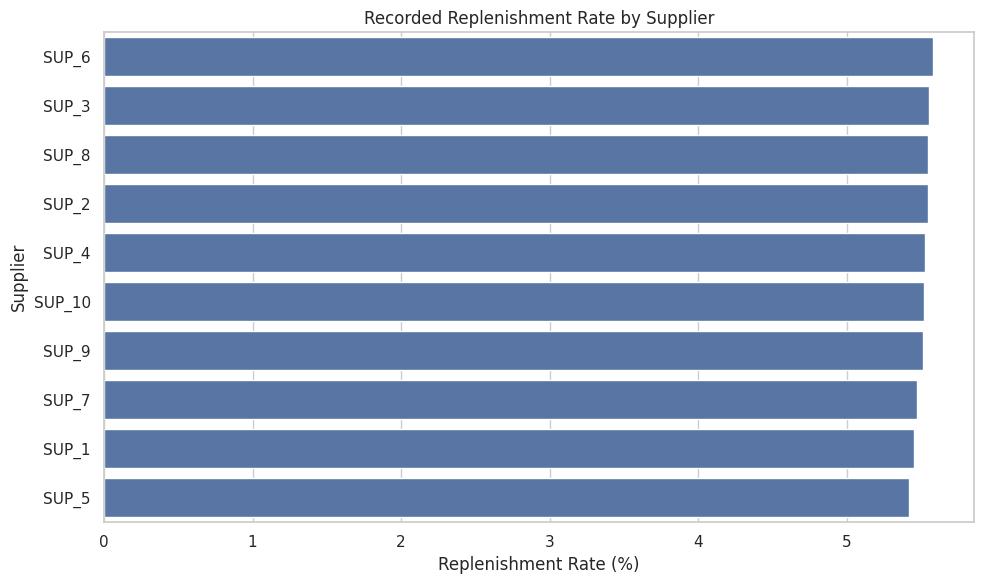

In [11]:
# Sort suppliers by replenishment rate for easier visual comparison.
supplier_rate_plot = supplier_replenishment.sort_values(
    by="Replenishment_Rate_Percent",
    ascending=False
)

# Create a horizontal bar chart of supplier replenishment rates.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=supplier_rate_plot,
    x="Replenishment_Rate_Percent",
    y=supplier_rate_plot.index
)

# Add descriptive chart labels.
plt.title("Recorded Replenishment Rate by Supplier")
plt.xlabel("Replenishment Rate (%)")
plt.ylabel("Supplier")

# Display the chart.
plt.tight_layout()
plt.show()

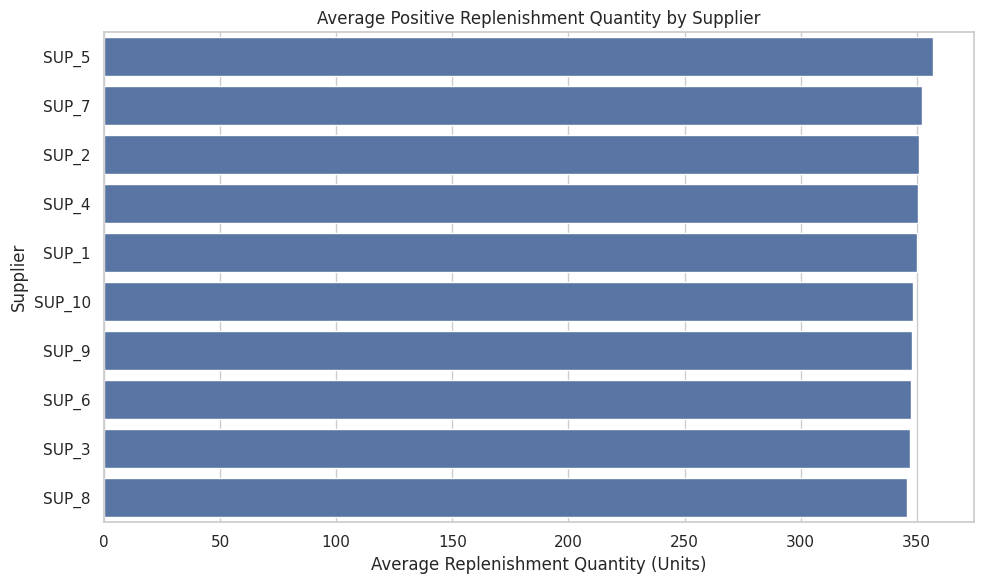

In [12]:
# Sort suppliers by average positive replenishment quantity.
supplier_quantity_plot = supplier_replenishment.sort_values(
    by="Average_Positive_Replenishment_Quantity",
    ascending=False
)

# Create a horizontal bar chart.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=supplier_quantity_plot,
    x="Average_Positive_Replenishment_Quantity",
    y=supplier_quantity_plot.index
)

# Add descriptive chart labels.
plt.title("Average Positive Replenishment Quantity by Supplier")
plt.xlabel("Average Replenishment Quantity (Units)")
plt.ylabel("Supplier")

# Display the chart.
plt.tight_layout()
plt.show()

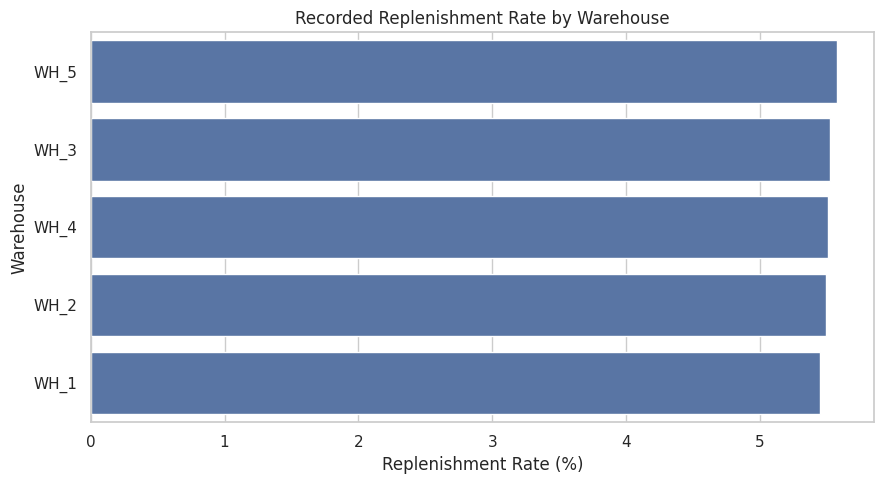

In [13]:
# Sort warehouses by replenishment rate.
warehouse_rate_plot = warehouse_replenishment.sort_values(
    by="Replenishment_Rate_Percent",
    ascending=False
)

# Create a horizontal bar chart.
plt.figure(figsize=(9, 5))

sns.barplot(
    data=warehouse_rate_plot,
    x="Replenishment_Rate_Percent",
    y=warehouse_rate_plot.index
)

# Add descriptive chart labels.
plt.title("Recorded Replenishment Rate by Warehouse")
plt.xlabel("Replenishment Rate (%)")
plt.ylabel("Warehouse")

# Display the chart.
plt.tight_layout()
plt.show()

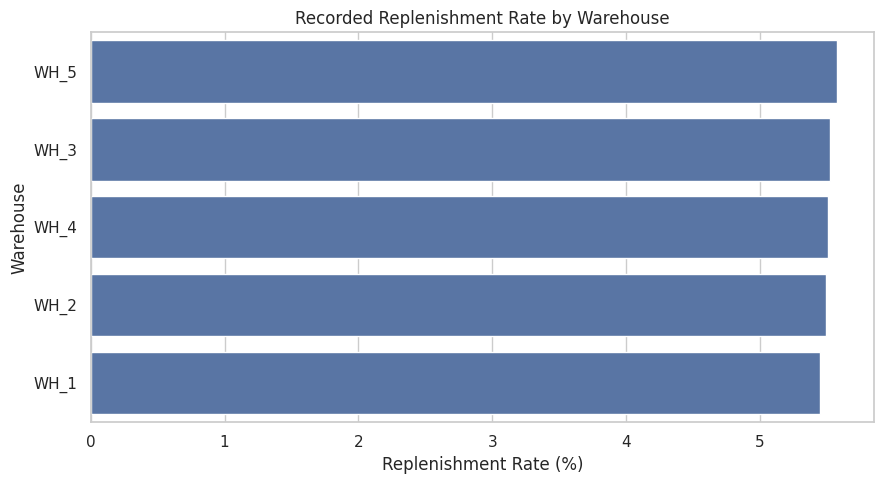

In [14]:
# Sort warehouses by replenishment rate.
warehouse_rate_plot = warehouse_replenishment.sort_values(
    by="Replenishment_Rate_Percent",
    ascending=False
)

# Create a horizontal bar chart.
plt.figure(figsize=(9, 5))

sns.barplot(
    data=warehouse_rate_plot,
    x="Replenishment_Rate_Percent",
    y=warehouse_rate_plot.index
)

# Add descriptive chart labels.
plt.title("Recorded Replenishment Rate by Warehouse")
plt.xlabel("Replenishment Rate (%)")
plt.ylabel("Warehouse")

# Display the chart.
plt.tight_layout()
plt.show()

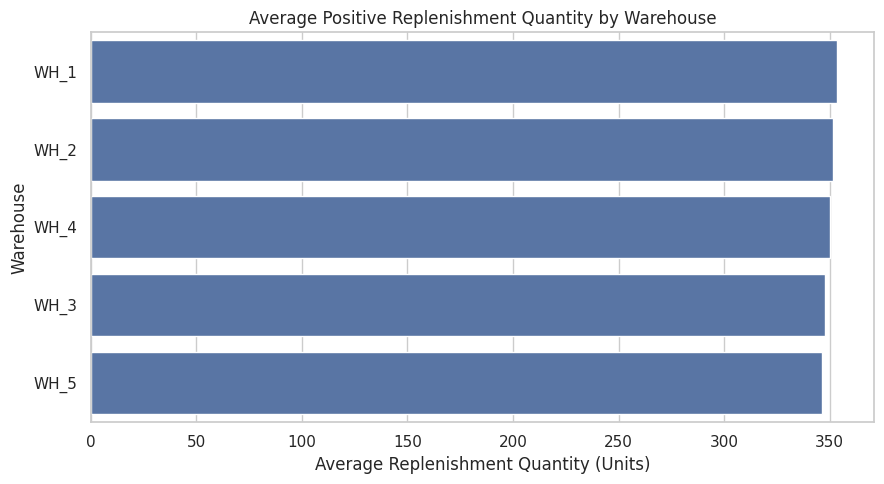

In [17]:
# Sort warehouses by average positive replenishment quantity.
warehouse_quantity_plot = warehouse_replenishment.sort_values(
    by="Average_Positive_Replenishment_Quantity",
    ascending=False
)

# Create a horizontal bar chart.
plt.figure(figsize=(9, 5))

sns.barplot(
    data=warehouse_quantity_plot,
    x="Average_Positive_Replenishment_Quantity",
    y=warehouse_quantity_plot.index
)

# Add descriptive chart labels.
plt.title("Average Positive Replenishment Quantity by Warehouse")
plt.xlabel("Average Replenishment Quantity (Units)")
plt.ylabel("Warehouse")

# Display the chart.
plt.tight_layout()
plt.show()

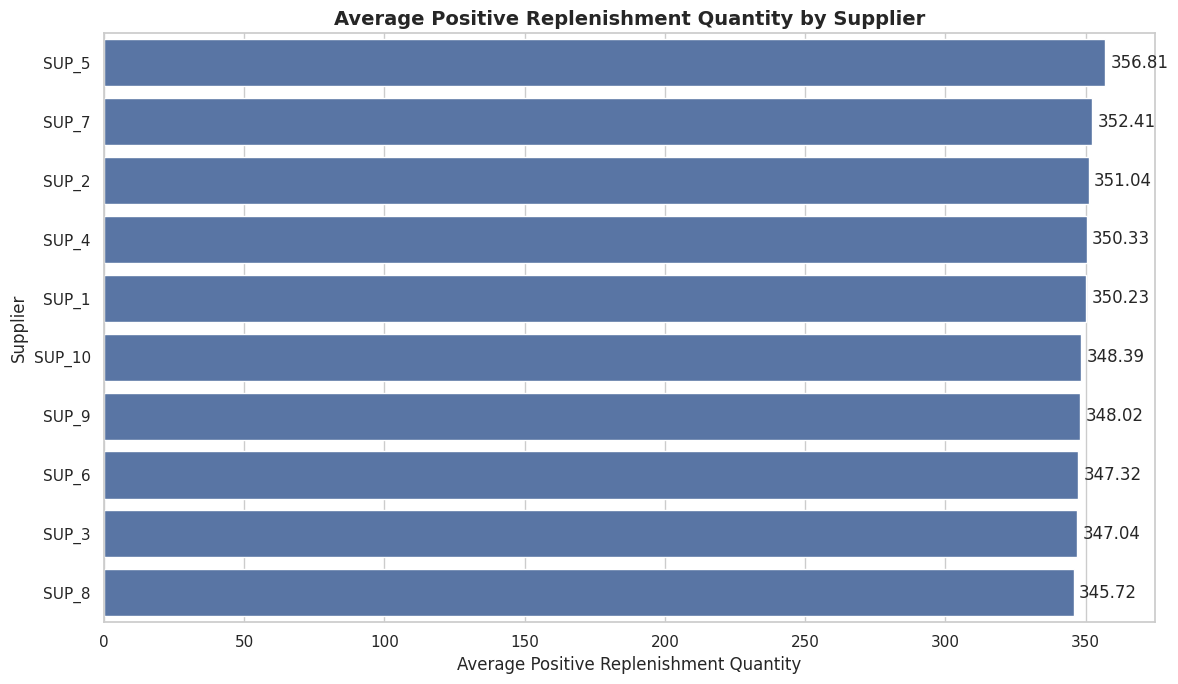

In [18]:

# ============================================================
# VISUALISATION 2: AVERAGE POSITIVE REPLENISHMENT QUANTITY
# BY SUPPLIER
# ============================================================

# Create a figure with a suitable size.
plt.figure(figsize=(12, 7))

# Create a horizontal bar chart.
ax = sns.barplot(
    data=supplier_replenishment.sort_values(
        "Average_Positive_Replenishment_Quantity",
        ascending=False
    ),
    x="Average_Positive_Replenishment_Quantity",
    y="Supplier_ID"
)

# Add a descriptive chart title.
plt.title(
    "Average Positive Replenishment Quantity by Supplier",
    fontsize=14,
    fontweight="bold"
)

# Label the horizontal and vertical axes.
plt.xlabel("Average Positive Replenishment Quantity")
plt.ylabel("Supplier")

# Add numerical labels to the bars.
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4
    )

# Adjust the layout to prevent overlapping elements.
plt.tight_layout()

# Display the chart.
plt.show()


### Average Positive Replenishment Quantity by Supplier

The analysis examined the average recorded replenishment quantity for observations where `Order_Quantity` was greater than zero.

SUP_5 recorded the highest average positive replenishment quantity at approximately 356.81 units, while SUP_8 recorded the lowest at approximately 345.72 units. The overall average across all suppliers was approximately 349.83 units.

The difference between the highest and lowest supplier averages was 11.09 units. This indicates relatively limited variation in average positive replenishment quantities across the suppliers.

These findings are descriptive and do not establish differences in supplier efficiency, reliability, or operational performance.

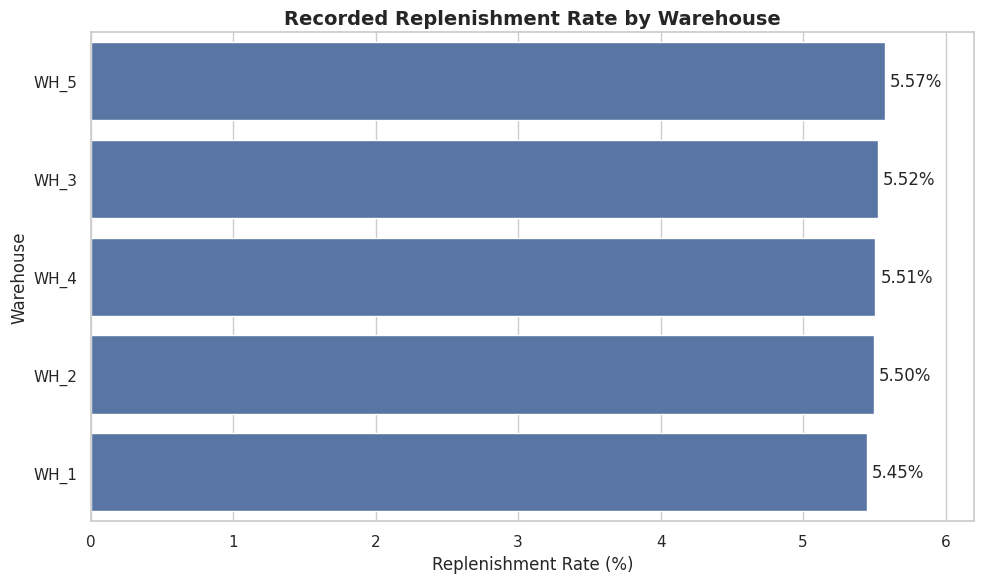

In [19]:

# ============================================================
# VISUALISATION 3: REPLENISHMENT RATE BY WAREHOUSE
# ============================================================

# Sort warehouses by replenishment rate, from highest to lowest.
warehouse_plot = warehouse_replenishment.sort_values(
    "Replenishment_Rate_Percent",
    ascending=False
)

# Create the figure.
plt.figure(figsize=(10, 6))

# Create a horizontal bar chart.
ax = sns.barplot(
    data=warehouse_plot,
    x="Replenishment_Rate_Percent",
    y="Warehouse_ID"
)

# Add the chart title.
plt.title(
    "Recorded Replenishment Rate by Warehouse",
    fontsize=14,
    fontweight="bold"
)

# Label the axes.
plt.xlabel("Replenishment Rate (%)")
plt.ylabel("Warehouse")

# Display percentage values on the bars.
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4
    )

# Start the horizontal axis at zero.
ax.set_xlim(0, 6.2)

# Adjust spacing.
plt.tight_layout()

# Display the chart.
plt.show()


### Warehouse-Level Recorded Replenishment Rate

The warehouse-level analysis revealed relatively consistent recorded replenishment rates across all five warehouses.

WH_5 recorded the highest replenishment rate at 5.57%, while WH_1 recorded the lowest at 5.45%. The difference between these warehouses was 0.12 percentage points.

Each warehouse contributed 18,250 observations and included all 50 SKUs, providing an equal observation base for descriptive comparison.

The relatively narrow variation suggests that recorded replenishment frequency was broadly similar across the warehouses during the observation period.

These results do not establish differences in warehouse efficiency or operational performance. Further analysis involving inventory turnover, stock availability, demand fulfilment and operating costs would be required to evaluate warehouse performance.

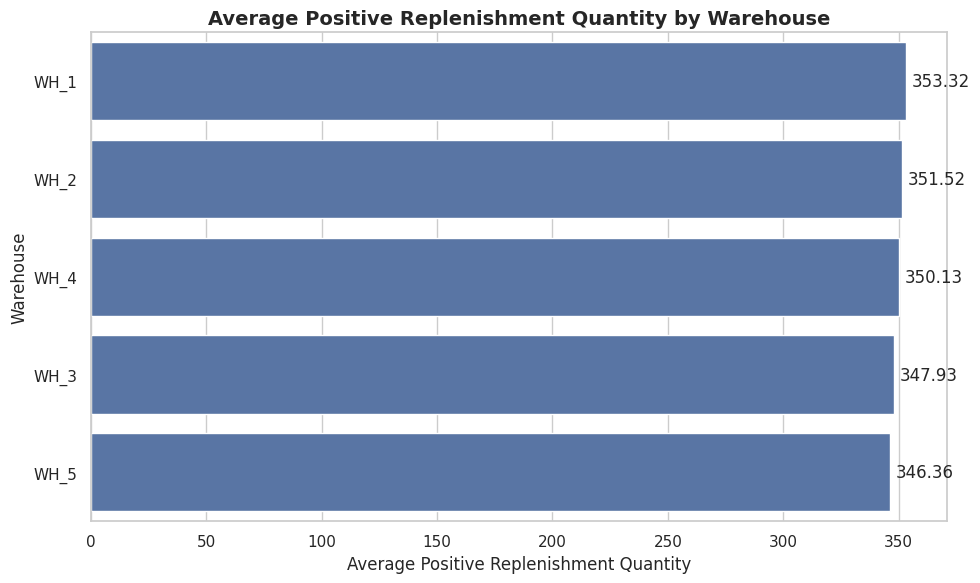

In [20]:

# ============================================================
# VISUALISATION 4: AVERAGE POSITIVE REPLENISHMENT QUANTITY
# BY WAREHOUSE
# ============================================================

# Sort warehouses by average positive replenishment quantity.
warehouse_quantity_plot = warehouse_replenishment.sort_values(
    "Average_Positive_Replenishment_Quantity",
    ascending=False
)

# Create the figure.
plt.figure(figsize=(10, 6))

# Generate the horizontal bar chart.
ax = sns.barplot(
    data=warehouse_quantity_plot,
    x="Average_Positive_Replenishment_Quantity",
    y="Warehouse_ID"
)

# Add the chart title.
plt.title(
    "Average Positive Replenishment Quantity by Warehouse",
    fontsize=14,
    fontweight="bold"
)

# Label both axes.
plt.xlabel("Average Positive Replenishment Quantity")
plt.ylabel("Warehouse")

# Add numerical labels to the bars.
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4
    )

# Adjust the layout.
plt.tight_layout()

# Display the chart.
plt.show()


### Average Positive Replenishment Quantity by Warehouse

The analysis compared average recorded replenishment quantities across the five warehouses, considering only observations where `Order_Quantity` was greater than zero.

WH_1 recorded the highest average positive replenishment quantity at approximately 353.32 units, while WH_5 recorded the lowest at approximately 346.36 units. The difference between the two warehouses was 6.96 units.

The relatively small variation suggests that average positive replenishment quantities were broadly similar across warehouses during the observation period.

These findings are descriptive and do not independently establish differences in warehouse efficiency, inventory management effectiveness or operational performance.

## Replenishment Analysis: Overall Findings

The exploratory analysis identified 5,027 positive replenishment observations out of 91,250 total records, representing 5.51% of observations. The total recorded replenishment quantity was 1,758,615 units.

Supplier-level and warehouse-level comparisons revealed relatively consistent replenishment rates and average positive replenishment quantities.

Supplier replenishment rates ranged from 5.42% to 5.58%, while warehouse replenishment rates ranged from 5.45% to 5.57%. Average positive replenishment quantities ranged from 345.72 to 356.81 units across suppliers and from 346.36 to 353.32 units across warehouses.

Although some differences were observed, the descriptive results do not establish statistically significant differences or demonstrate operational superiority.

Further investigation could examine replenishment timing, inventory movements, demand patterns and the relationship between replenishment quantities and subsequent inventory levels.

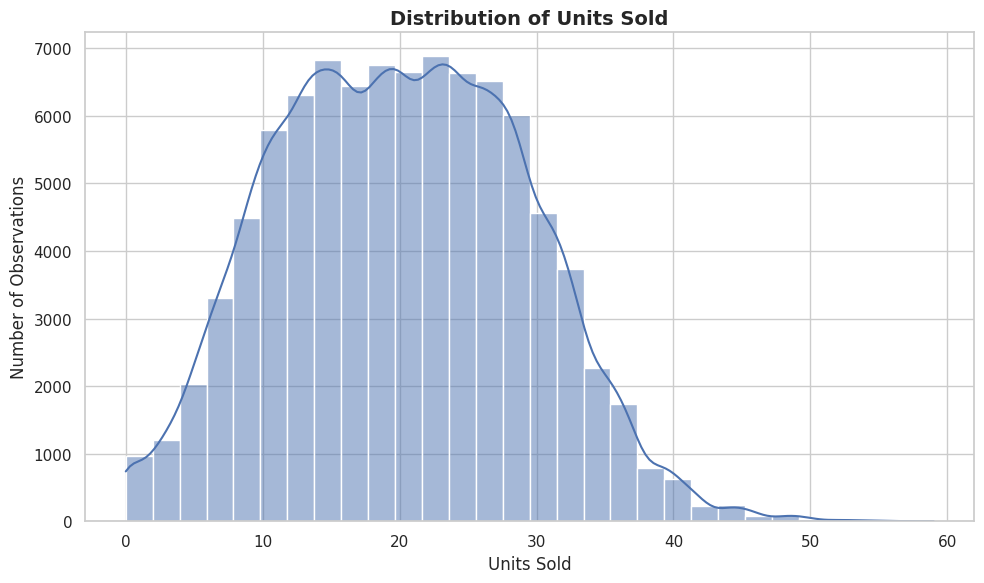

In [21]:

# ============================================================
# DEMAND AND SALES ANALYSIS
# VISUALISATION 1: UNITS SOLD DISTRIBUTION
# ============================================================

# Create a figure.
plt.figure(figsize=(10, 6))

# Plot the distribution of Units Sold.
sns.histplot(
    data=df,
    x="Units_Sold",
    bins=30,
    kde=True
)

# Add chart title and axis labels.
plt.title(
    "Distribution of Units Sold",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Units Sold")
plt.ylabel("Number of Observations")

# Adjust the layout.
plt.tight_layout()

# Display the chart.
plt.show()


In [22]:

# ============================================================
# UNITS SOLD: DESCRIPTIVE STATISTICS AND SKEWNESS
# ============================================================

# Calculate descriptive statistics for Units_Sold.
units_sold_statistics = df["Units_Sold"].describe()

# Calculate the skewness of Units_Sold.
units_sold_skewness = df["Units_Sold"].skew()

# Calculate the mean and median.
units_sold_mean = df["Units_Sold"].mean()
units_sold_median = df["Units_Sold"].median()

# Display descriptive statistics.
print("UNITS SOLD: DESCRIPTIVE STATISTICS")
display(units_sold_statistics.to_frame(name="Value"))

# Display skewness.
print("\nSkewness:", round(units_sold_skewness, 4))

# Display mean and median.
print("Mean:", round(units_sold_mean, 2))
print("Median:", round(units_sold_median, 2))

# Interpret skewness using a simple descriptive rule.
if units_sold_skewness > 0.5:
    print("Interpretation: Positively skewed (right-skewed).")
elif units_sold_skewness < -0.5:
    print("Interpretation: Negatively skewed (left-skewed).")
else:
    print("Interpretation: Approximately symmetric based on the skewness measure.")


UNITS SOLD: DESCRIPTIVE STATISTICS


,Value
count,91250.00
mean,20.05
std,9.07
min,0.00
25%,13.00
50%,20.00
75%,27.00
max,59.00



Skewness: 0.1371
Mean: 20.05
Median: 20.0
Interpretation: Approximately symmetric based on the skewness measure.


### Units Sold: Distribution and Descriptive Statistics

The distribution of `Units_Sold` was examined using descriptive statistics, a histogram and the skewness measure.

The dataset contains 91,250 observations, with an average daily recorded sales quantity of approximately 20.05 units and a median of 20 units. The standard deviation is 9.07 units.

The first and third quartiles are 13 and 27 units, respectively, resulting in an interquartile range of 14 units.

The calculated skewness is 0.1371, indicating an approximately symmetric distribution with a slight positive skew. The close relationship between the mean and median supports this descriptive interpretation.

Overall, recorded sales quantities are reasonably centred around 20 units, although individual observations vary. Approximate symmetry does not establish that the data follows a normal distribution.

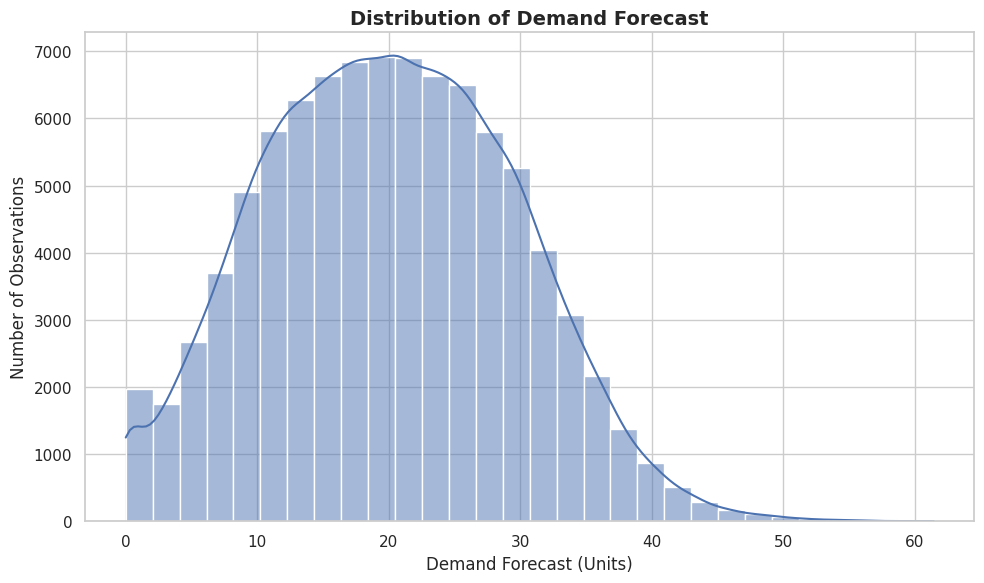

In [23]:

# ============================================================
# DEMAND AND SALES ANALYSIS
# VISUALISATION 2: DEMAND FORECAST DISTRIBUTION
# ============================================================

# Create a figure.
plt.figure(figsize=(10, 6))

# Plot the distribution of Demand_Forecast.
sns.histplot(
    data=df,
    x="Demand_Forecast",
    bins=30,
    kde=True
)

# Add a descriptive title.
plt.title(
    "Distribution of Demand Forecast",
    fontsize=14,
    fontweight="bold"
)

# Label the axes.
plt.xlabel("Demand Forecast (Units)")
plt.ylabel("Number of Observations")

# Adjust the layout.
plt.tight_layout()

# Display the chart.
plt.show()


In [24]:

# ============================================================
# DEMAND FORECAST: DESCRIPTIVE STATISTICS AND SKEWNESS
# ============================================================

# Calculate descriptive statistics.
demand_forecast_statistics = df["Demand_Forecast"].describe()

# Calculate skewness.
demand_forecast_skewness = df["Demand_Forecast"].skew()

# Calculate mean and median.
demand_forecast_mean = df["Demand_Forecast"].mean()
demand_forecast_median = df["Demand_Forecast"].median()

# Display descriptive statistics.
print("DEMAND FORECAST: DESCRIPTIVE STATISTICS")
display(
    demand_forecast_statistics.to_frame(name="Value")
)

# Display skewness.
print("\nSkewness:", round(demand_forecast_skewness, 4))

# Display mean and median.
print("Mean:", round(demand_forecast_mean, 2))
print("Median:", round(demand_forecast_median, 2))

# Interpret the skewness descriptively.
if demand_forecast_skewness > 0.5:
    print("Interpretation: Positively skewed (right-skewed).")
elif demand_forecast_skewness < -0.5:
    print("Interpretation: Negatively skewed (left-skewed).")
else:
    print("Interpretation: Approximately symmetric based on skewness.")


DEMAND FORECAST: DESCRIPTIVE STATISTICS


,Value
count,91250.00
mean,20.08
std,9.50
min,0.00
25%,12.95
50%,19.95
75%,26.93
max,61.42



Skewness: 0.1418
Mean: 20.08
Median: 19.95
Interpretation: Approximately symmetric based on skewness.


### Demand Forecast: Distribution and Descriptive Statistics

The distribution of `Demand_Forecast` was examined using descriptive statistics, a histogram and the skewness measure.

The dataset contains 91,250 observations, with an average forecasted demand of approximately 20.08 units and a median of 19.95 units. The standard deviation is 9.50 units.

The first and third quartiles are 12.95 and 26.93 units, respectively, resulting in an interquartile range of 13.98 units.

The calculated skewness is 0.1418, indicating an approximately symmetric distribution with a slight positive skew.

Compared with actual recorded sales, forecasted demand has a slightly higher mean and standard deviation. These differences provide an initial descriptive comparison but do not establish forecast accuracy.

In [25]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 1: CALCULATE FORECAST ERRORS
# ============================================================

# Create a separate working DataFrame for comparison.
df_forecast_analysis = df.copy()

# Calculate the difference between actual sales and forecasted demand.
# Positive values indicate sales exceeded forecasted demand.
# Negative values indicate sales were below forecasted demand.
df_forecast_analysis["Forecast_Error"] = (
    df_forecast_analysis["Units_Sold"]
    - df_forecast_analysis["Demand_Forecast"]
)

# Calculate the absolute forecast error.
df_forecast_analysis["Absolute_Forecast_Error"] = (
    df_forecast_analysis["Forecast_Error"].abs()
)

# Display the first five observations.
display(
    df_forecast_analysis[
        [
            "Date",
            "SKU_ID",
            "Warehouse_ID",
            "Units_Sold",
            "Demand_Forecast",
            "Forecast_Error",
            "Absolute_Forecast_Error"
        ]
    ].head()
)


,Date,SKU_ID,Warehouse_ID,Units_Sold,Demand_Forecast,Forecast_Error,Absolute_Forecast_Error
0,2024-01-01,SKU_1,WH_1,10,8.52,1.48,1.48
1,2024-01-02,SKU_1,WH_1,17,18.63,-1.63,1.63
2,2024-01-03,SKU_1,WH_1,35,39.62,-4.62,4.62
3,2024-01-04,SKU_1,WH_1,24,19.43,4.57,4.57
4,2024-01-05,SKU_1,WH_1,21,18.70,2.30,2.30


In [26]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 2: CALCULATE FORECAST EVALUATION METRICS
# ============================================================

# Import the required evaluation functions.
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Define actual sales and forecasted demand.
actual_sales = df_forecast_analysis["Units_Sold"]
forecasted_demand = df_forecast_analysis["Demand_Forecast"]

# Calculate Mean Absolute Error (MAE).
# MAE measures the average absolute difference between sales and forecasts.
mae = mean_absolute_error(actual_sales, forecasted_demand)

# Calculate Root Mean Squared Error (RMSE).
# RMSE gives greater weight to larger forecasting errors.
rmse = np.sqrt(mean_squared_error(actual_sales, forecasted_demand))

# Calculate Mean Forecast Error (MFE).
# With our error definition, positive values indicate underforecasting.
# Negative values indicate overforecasting.
mean_forecast_error = df_forecast_analysis["Forecast_Error"].mean()

# Display the evaluation metrics.
print("FORECAST EVALUATION RESULTS")
print("=" * 40)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Forecast Error (MFE): {mean_forecast_error:.4f}")


FORECAST EVALUATION RESULTS
Mean Absolute Error (MAE): 2.3798
Root Mean Squared Error (RMSE): 2.9874
Mean Forecast Error (MFE): -0.0275


### Actual Sales vs Demand Forecast: Forecast Evaluation

The recorded demand forecasts were evaluated against actual sales using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and Mean Forecast Error (MFE).

The calculated MAE is 2.3798 units, indicating that the average absolute difference between actual sales and forecasted demand is approximately 2.38 units per observation.

The RMSE is 2.9874 units. Its higher value compared with the MAE indicates that larger forecasting errors have a greater influence on this metric.

The MFE is -0.0275 units, suggesting that the average signed forecast error is very close to zero, with a negligible overall tendency towards overforecasting.

Although the results indicate limited average directional bias, this does not mean that individual forecasts are consistently accurate. Positive and negative errors may offset one another.

These metrics describe the recorded forecasts in the dataset. They should not be interpreted as evidence of out-of-sample predictive performance because the forecast-generation process and forecast horizon have not been established.

In [27]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 3: ANALYSE THE DISTRIBUTION OF FORECAST ERRORS
# ============================================================

# Calculate descriptive statistics for signed forecast errors.
print("SIGNED FORECAST ERROR SUMMARY")
display(df_forecast_analysis["Forecast_Error"].describe())

# Calculate descriptive statistics for absolute forecast errors.
print("ABSOLUTE FORECAST ERROR SUMMARY")
display(df_forecast_analysis["Absolute_Forecast_Error"].describe())

# Calculate the percentage of observations within selected error thresholds.
error_thresholds = [1, 2, 3, 5]

for threshold in error_thresholds:
    # Count observations whose absolute error is within the threshold.
    count_within_threshold = (
        df_forecast_analysis["Absolute_Forecast_Error"] <= threshold
    ).sum()

    # Convert the count into a percentage of all observations.
    percentage = (
        count_within_threshold / len(df_forecast_analysis)
    ) * 100

    print(
        f"Absolute error <= {threshold} units: "
        f"{count_within_threshold:,} observations "
        f"({percentage:.2f}%)"
    )



SIGNED FORECAST ERROR SUMMARY


,Forecast_Error
count,91250.00
mean,-0.03
std,2.99
min,-14.08
25%,-2.03
50%,-0.01
75%,1.99
max,13.00


ABSOLUTE FORECAST ERROR SUMMARY


,Absolute_Forecast_Error
count,91250.00
mean,2.38
std,1.81
min,0.00
25%,0.95
50%,2.00
75%,3.44
max,14.08


Absolute error <= 1 units: 24,222 observations (26.54%)
Absolute error <= 2 units: 45,662 observations (50.04%)
Absolute error <= 3 units: 62,712 observations (68.73%)
Absolute error <= 5 units: 82,708 observations (90.64%)



### Forecast Error Distribution and Threshold Analysis

The distribution of signed and absolute forecast errors was examined across 91,250 observations.

The mean signed forecast error was approximately -0.03 units, while the median was -0.01 units. Both values indicate that the errors are centred close to zero, suggesting very little overall directional bias.

The mean absolute error was 2.38 units, and the median absolute error was 2.00 units. The 75th percentile of absolute errors was 3.44 units, indicating that 75% of observations had absolute errors no greater than approximately 3.44 units.

The threshold analysis showed that:

- 26.54% of observations had absolute errors of one unit or less.
- 50.04% had absolute errors of two units or less.
- 68.73% had absolute errors of three units or less.
- 90.64% had absolute errors of five units or less.

The maximum absolute error was 14.08 units, indicating that some observations had considerably larger errors than the typical observation.

Overall, the recorded forecasts generally had relatively small absolute errors, although larger individual errors were also present. These findings are descriptive and do not establish out-of-sample forecasting performance.


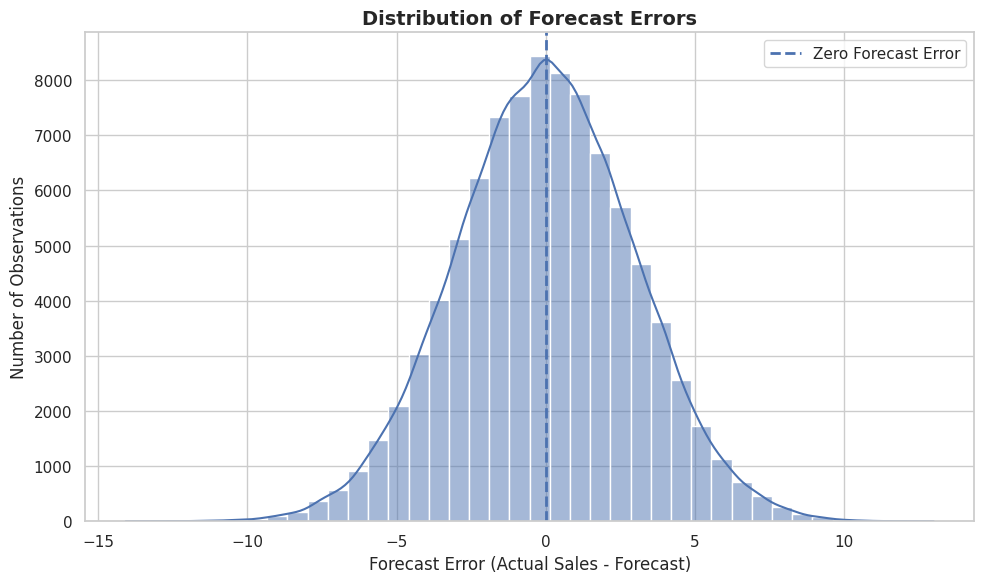

In [28]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 4: VISUALISE THE SIGNED FORECAST ERROR DISTRIBUTION
# ============================================================

# Create a figure for the signed forecast error distribution.
plt.figure(figsize=(10, 6))

# Plot the distribution of signed forecast errors.
sns.histplot(
    data=df_forecast_analysis,
    x="Forecast_Error",
    bins=40,
    kde=True
)

# Add a vertical reference line at zero error.
# Errors to the left indicate overforecasting.
# Errors to the right indicate underforecasting.
plt.axvline(
    x=0,
    linestyle="--",
    linewidth=2,
    label="Zero Forecast Error"
)

# Add chart labels and title.
plt.title(
    "Distribution of Forecast Errors",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Forecast Error (Actual Sales - Forecast)")
plt.ylabel("Number of Observations")
plt.legend()

# Improve spacing and display the chart.
plt.tight_layout()
plt.show()



### Visual Analysis of the Forecast Error Distribution

A histogram with a KDE curve was used to examine the distribution of signed forecast errors.

The distribution appears approximately symmetrical and concentrated around zero, with fewer observations towards the negative and positive extremes.

This visual observation is consistent with the calculated mean forecast error of -0.0275 and median forecast error of approximately -0.01.

Negative errors represent overforecasting, while positive errors represent underforecasting.

The distribution suggests that both types of forecasting errors occur, with relatively few observations having large errors.

Although the distribution appears approximately bell-shaped, this visual assessment alone does not establish normality.


In [29]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 5: FORECAST ERROR ANALYSIS BY WAREHOUSE
# ============================================================

# Group observations by warehouse and calculate forecast metrics.
warehouse_forecast_summary = (
    df_forecast_analysis
    .groupby("Warehouse_ID")
    .agg(
        Total_Observations=("Forecast_Error", "count"),
        Mean_Forecast_Error=("Forecast_Error", "mean"),
        MAE=("Absolute_Forecast_Error", "mean"),
        RMSE=("Forecast_Error", lambda x: np.sqrt(np.mean(x ** 2))),
        Average_Actual_Sales=("Units_Sold", "mean"),
        Average_Forecast=("Demand_Forecast", "mean")
    )
    .reset_index()
)

# Sort warehouses by Mean Absolute Error, from lowest to highest.
warehouse_forecast_summary = (
    warehouse_forecast_summary
    .sort_values("MAE")
    .reset_index(drop=True)
)

# Display the warehouse-level forecast evaluation results.
display(warehouse_forecast_summary.round(4))


,Warehouse_ID,Total_Observations,Mean_Forecast_Error,MAE,RMSE,Average_Actual_Sales,Average_Forecast
0,WH_1,18250,-0.03,2.36,2.97,20.10,20.14
1,WH_5,18250,-0.04,2.37,2.98,20.01,20.05
2,WH_2,18250,-0.05,2.39,3.00,20.06,20.11
3,WH_3,18250,-0.02,2.39,3.00,20.06,20.08
4,WH_4,18250,0.01,2.39,2.99,20.04,20.04


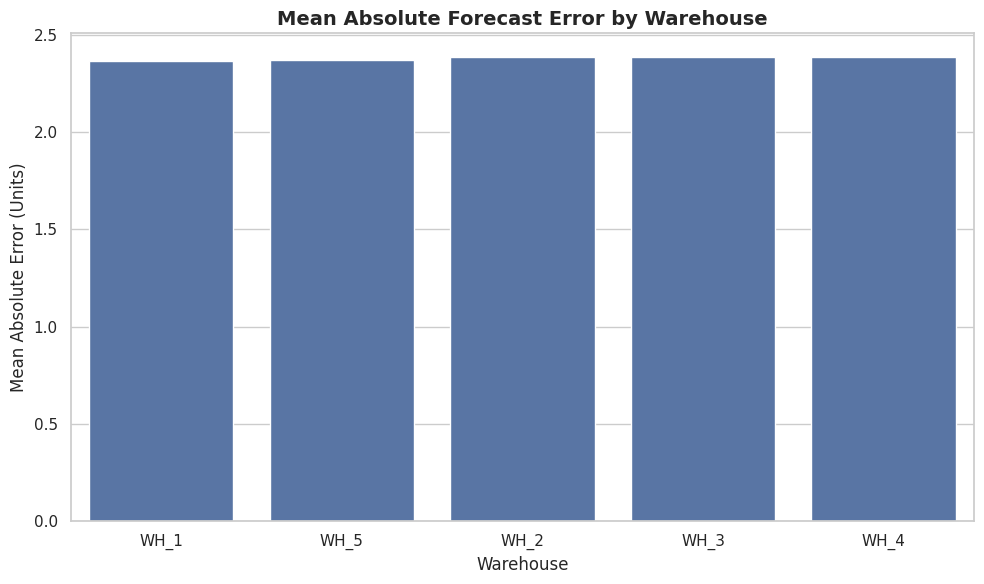

In [30]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 6: VISUALISE MAE BY WAREHOUSE
# ============================================================

# Create a figure for warehouse-level MAE comparison.
plt.figure(figsize=(10, 6))

# Plot the Mean Absolute Error for each warehouse.
sns.barplot(
    data=warehouse_forecast_summary,
    x="Warehouse_ID",
    y="MAE"
)

# Add a descriptive chart title and axis labels.
plt.title(
    "Mean Absolute Forecast Error by Warehouse",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Warehouse")
plt.ylabel("Mean Absolute Error (Units)")

# Display the chart.
plt.tight_layout()
plt.show()



### Forecast Evaluation by Warehouse

Forecast errors were evaluated separately across the five warehouses using MAE, RMSE and Mean Forecast Error.

Each warehouse contributed 18,250 observations.

WH_1 recorded the lowest MAE at 2.36 units, followed by WH_5 at 2.37 units. WH_2, WH_3 and WH_4 each recorded an MAE of approximately 2.39 units.

The RMSE values ranged from 2.97 to 3.00 units, indicating relatively similar error magnitudes across warehouses.

Mean Forecast Error ranged from -0.05 to 0.01 units. These values indicate negligible average directional bias across the warehouses.

Overall, the warehouse-level results show relatively small differences in recorded forecast errors. WH_1 had the lowest observed MAE, but the differences are descriptive and do not establish statistically significant differences in forecasting performance or operational efficiency.


In [31]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 7: FORECAST EVALUATION BY SKU
# ============================================================

# Group observations by SKU and calculate forecast evaluation metrics.
sku_forecast_summary = (
    df_forecast_analysis
    .groupby("SKU_ID")
    .agg(
        Total_Observations=("Forecast_Error", "count"),
        Mean_Forecast_Error=("Forecast_Error", "mean"),
        MAE=("Absolute_Forecast_Error", "mean"),
        RMSE=("Forecast_Error", lambda x: np.sqrt(np.mean(x ** 2))),
        Average_Actual_Sales=("Units_Sold", "mean"),
        Average_Forecast=("Demand_Forecast", "mean")
    )
    .reset_index()
)

# Sort SKUs from the lowest to the highest MAE.
sku_forecast_summary = (
    sku_forecast_summary
    .sort_values("MAE")
    .reset_index(drop=True)
)

# Display the first 10 SKUs with the lowest MAE.
print("10 SKUs WITH THE LOWEST MAE")
display(sku_forecast_summary.head(10).round(4))

# Display the 10 SKUs with the highest MAE.
print("10 SKUs WITH THE HIGHEST MAE")
display(sku_forecast_summary.tail(10).round(4))


10 SKUs WITH THE LOWEST MAE


,SKU_ID,Total_Observations,Mean_Forecast_Error,MAE,RMSE,Average_Actual_Sales,Average_Forecast
0,SKU_9,1825,0.05,2.30,2.89,20.19,20.14
1,SKU_27,1825,0.03,2.31,2.92,19.96,19.92
2,SKU_16,1825,-0.09,2.31,2.93,20.00,20.09
3,SKU_14,1825,-0.03,2.32,2.93,20.05,20.07
4,SKU_11,1825,-0.05,2.32,2.93,19.92,19.97
5,SKU_39,1825,0.07,2.33,2.92,20.05,19.98
6,SKU_20,1825,-0.07,2.33,2.94,20.13,20.20
7,SKU_8,1825,-0.06,2.34,2.94,20.11,20.17
8,SKU_26,1825,-0.13,2.34,2.93,19.94,20.08
9,SKU_19,1825,0.02,2.34,2.95,19.87,19.85


10 SKUs WITH THE HIGHEST MAE


,SKU_ID,Total_Observations,Mean_Forecast_Error,MAE,RMSE,Average_Actual_Sales,Average_Forecast
40,SKU_10,1825,-0.03,2.42,3.05,20.04,20.07
41,SKU_22,1825,-0.07,2.42,3.02,20.08,20.15
42,SKU_28,1825,-0.00,2.42,3.01,19.99,19.99
43,SKU_36,1825,0.11,2.42,3.07,20.05,19.94
44,SKU_17,1825,0.02,2.42,3.01,19.97,19.95
45,SKU_29,1825,0.05,2.43,3.07,20.13,20.08
46,SKU_24,1825,-0.10,2.44,3.04,19.93,20.04
47,SKU_47,1825,0.02,2.44,3.06,20.23,20.21
48,SKU_44,1825,0.02,2.45,3.04,20.10,20.08
49,SKU_23,1825,-0.01,2.45,3.05,20.11,20.12



### Forecast Evaluation by SKU

Forecast evaluation metrics were calculated separately for all 50 SKUs. Each SKU contributed 1,825 observations.

SKU_9 recorded the lowest Mean Absolute Error (MAE) at 2.30 units, while SKU_23 recorded the highest MAE at 2.45 units.

The difference between the highest and lowest SKU-level MAE was approximately 0.15 units, indicating relatively limited variation in average absolute forecast errors across the two extremes.

Mean Forecast Error values were also close to zero among the displayed SKUs, suggesting limited average directional bias.

The average actual sales and average forecasted demand were generally similar across the displayed products.

Overall, the results indicate relatively consistent recorded forecast error magnitudes across the examined SKUs. However, these descriptive comparisons do not establish statistically significant differences or demonstrate that particular products are inherently easier to forecast.


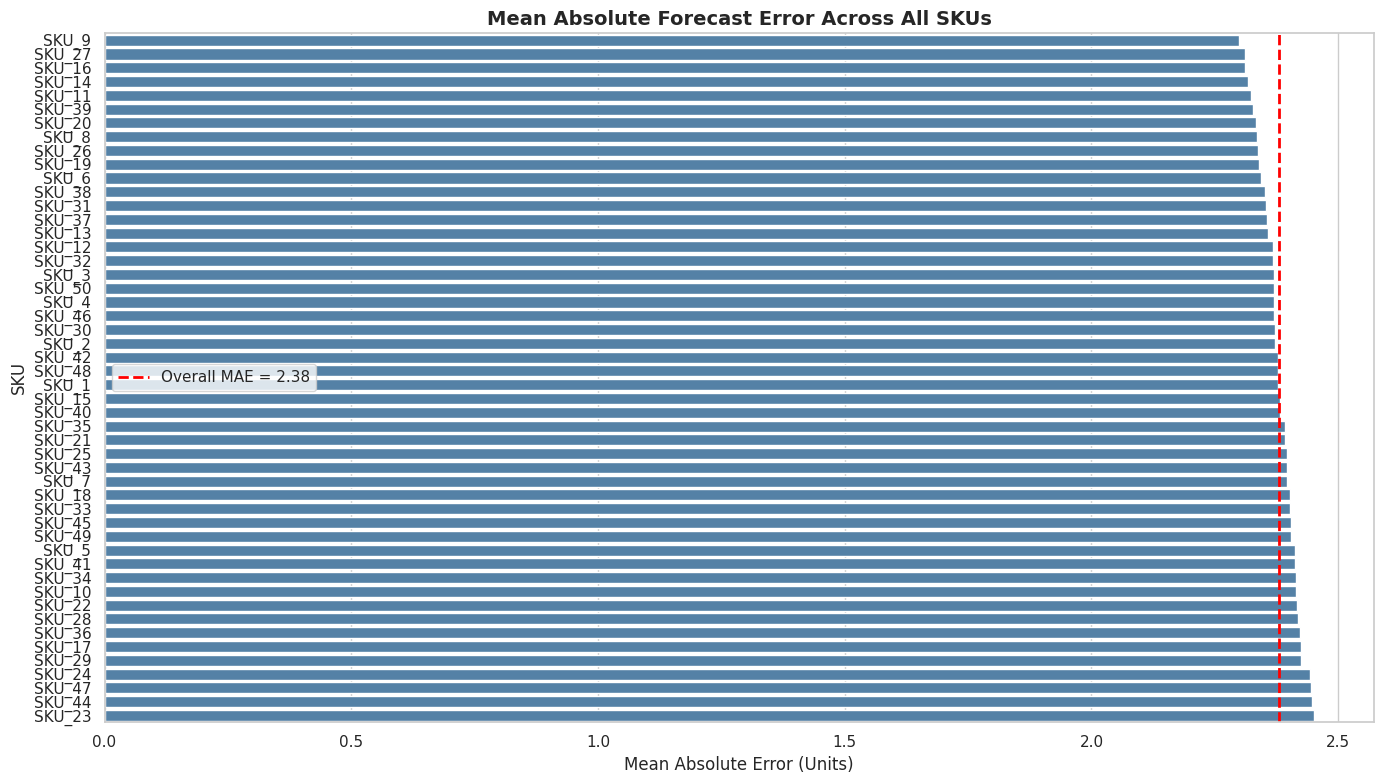

In [32]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 8: VISUALISE MAE ACROSS ALL SKUs
# ============================================================

# Create a figure for the SKU-level MAE comparison.
plt.figure(figsize=(14, 8))

# Plot MAE for all SKUs, ordered from lowest to highest.
sns.barplot(
    data=sku_forecast_summary,
    x="MAE",
    y="SKU_ID",
    color="steelblue"
)

# Add a reference line showing the overall dataset MAE.
plt.axvline(
    x=mae,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall MAE = {mae:.2f}"
)

# Add chart title and axis labels.
plt.title(
    "Mean Absolute Forecast Error Across All SKUs",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Mean Absolute Error (Units)")
plt.ylabel("SKU")

# Display the legend and chart.
plt.legend()
plt.tight_layout()
plt.show()



### Visual Comparison of Forecast Errors Across SKUs

A horizontal bar chart was used to compare Mean Absolute Error (MAE) across all 50 SKUs.

The SKUs were arranged in ascending order of MAE, with a vertical reference line representing the overall dataset MAE of approximately 2.38 units.

The chart shows that the MAE values are relatively close together, ranging from approximately 2.30 units for SKU_9 to 2.45 units for SKU_23.

Most bars are clustered around the overall MAE reference line, indicating limited variation in average absolute forecast errors across the products.

These findings are descriptive and do not establish statistically significant differences in forecasting performance between SKUs.


In [33]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 9: MONTHLY FORECAST EVALUATION
# ============================================================

# Extract the calendar month from the Date column.
df_forecast_analysis["Month"] = (
    df_forecast_analysis["Date"].dt.month
)

# Group observations by month and calculate forecast metrics.
monthly_forecast_summary = (
    df_forecast_analysis
    .groupby("Month")
    .agg(
        Total_Observations=("Forecast_Error", "count"),
        Mean_Forecast_Error=("Forecast_Error", "mean"),
        MAE=("Absolute_Forecast_Error", "mean"),
        RMSE=(
            "Forecast_Error",
            lambda x: np.sqrt(np.mean(x ** 2))
        ),
        Average_Actual_Sales=("Units_Sold", "mean"),
        Average_Forecast=("Demand_Forecast", "mean")
    )
    .reset_index()
)

# Create readable month names for the results.
monthly_forecast_summary["Month_Name"] = (
    pd.to_datetime(
        monthly_forecast_summary["Month"],
        format="%m"
    ).dt.strftime("%B")
)

# Arrange the columns for easier interpretation.
monthly_forecast_summary = monthly_forecast_summary[
    [
        "Month",
        "Month_Name",
        "Total_Observations",
        "Mean_Forecast_Error",
        "MAE",
        "RMSE",
        "Average_Actual_Sales",
        "Average_Forecast"
    ]
]

# Display the monthly forecast evaluation results.
display(monthly_forecast_summary.round(4))


,Month,Month_Name,Total_Observations,Mean_Forecast_Error,MAE,RMSE,Average_Actual_Sales,Average_Forecast
0,1,January,7750,-0.02,2.40,3.00,22.80,22.82
1,2,February,7250,-0.01,2.42,3.04,27.20,27.21
2,3,March,7750,-0.02,2.39,3.00,29.88,29.90
3,4,April,7500,0.04,2.38,2.98,29.84,29.80
4,5,May,7750,0.05,2.40,3.00,27.21,27.16
5,6,June,7500,-0.02,2.40,3.01,22.67,22.69
6,7,July,7750,-0.03,2.41,3.02,17.41,17.44
7,8,August,7750,-0.06,2.39,2.99,12.78,12.83
8,9,September,7500,-0.14,2.32,2.94,10.17,10.31
9,10,October,7750,-0.04,2.30,2.91,10.27,10.31



### Monthly Forecast Evaluation

Forecast evaluation metrics were calculated across the 12 months of 2024.

Monthly MAE values ranged from 2.30 to 2.42 units. October recorded the lowest MAE at 2.30 units, while February and December recorded the highest MAE at 2.42 units.

The relatively narrow MAE range indicates that average absolute forecast errors remained fairly stable throughout the year.

Mean Forecast Error ranged from -0.14 to 0.05 units. September recorded the strongest average overforecasting tendency, while May recorded the strongest average underforecasting tendency.

Average actual sales varied considerably across the year, reaching 29.88 units in March and declining to 10.17 units in September.

Despite these changes in average sales, monthly MAE remained relatively stable. This raises the possibility that the relative magnitude of forecast errors differs across months.

The observed monthly patterns are descriptive. A single year of observations is insufficient to establish recurring seasonal patterns or statistically significant differences in forecasting performance.


In [34]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 10: CALCULATE RELATIVE MONTHLY MAE
# ============================================================

# Create a copy of the monthly forecast summary.
monthly_forecast_summary = monthly_forecast_summary.copy()

# Calculate MAE as a percentage of average actual sales.
# This provides a scale-normalised comparison across months.
monthly_forecast_summary["Relative_MAE_Percent"] = (
    monthly_forecast_summary["MAE"]
    / monthly_forecast_summary["Average_Actual_Sales"]
) * 100

# Display the monthly MAE alongside the relative MAE.
display(
    monthly_forecast_summary[
        [
            "Month_Name",
            "MAE",
            "Average_Actual_Sales",
            "Relative_MAE_Percent"
        ]
    ].round(4)
)


,Month_Name,MAE,Average_Actual_Sales,Relative_MAE_Percent
0,January,2.40,22.80,10.52
1,February,2.42,27.20,8.89
2,March,2.39,29.88,8.01
3,April,2.38,29.84,7.96
4,May,2.40,27.21,8.83
5,June,2.40,22.67,10.59
6,July,2.41,17.41,13.86
7,August,2.39,12.78,18.69
8,September,2.32,10.17,22.80
9,October,2.30,10.27,22.38



### Relative Forecast Error Analysis by Month

Relative MAE was calculated by dividing monthly Mean Absolute Error by average actual sales and multiplying by 100.

The results reveal a considerable difference between absolute and relative forecast errors.

Although monthly MAE remained relatively stable, ranging from 2.30 to 2.42 units, Relative MAE ranged from 7.96% to 22.80%.

April recorded the lowest Relative MAE at 7.96%, while September recorded the highest at 22.80%. October followed closely at 22.38%.

The increase in Relative MAE from July onwards coincided with declining average actual sales. For example, April had average actual sales of 29.84 units and an MAE of 2.38 units, whereas September had average actual sales of 10.17 units and an MAE of 2.32 units.

This indicates that similarly sized absolute errors represent a larger proportion of sales when demand volumes are lower.

Overall, the findings demonstrate why absolute and scale-normalised error measures should be considered together when evaluating forecasting performance across periods with different sales levels.

Relative MAE is a descriptive measure and should not be interpreted as individual-level MAPE or proof of deteriorating forecasting model performance.


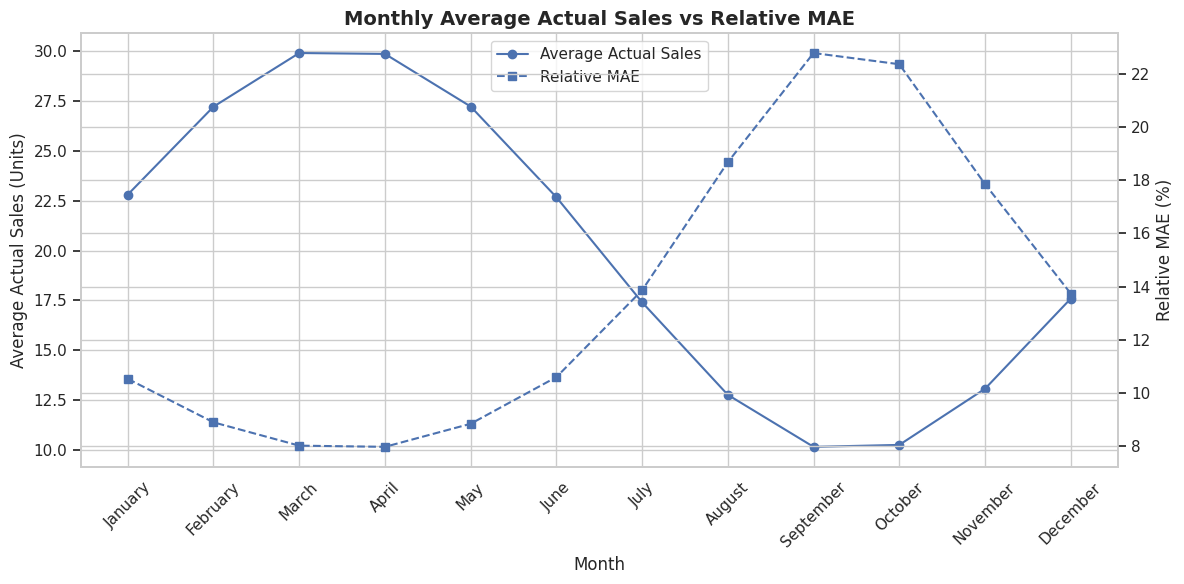

In [35]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 11: COMPARE MONTHLY SALES AND RELATIVE MAE
# ============================================================

# Create a figure for the comparison.
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot average actual sales on the first y-axis.
ax1.plot(
    monthly_forecast_summary["Month_Name"],
    monthly_forecast_summary["Average_Actual_Sales"],
    marker="o",
    label="Average Actual Sales"
)

# Add labels for the first y-axis.
ax1.set_xlabel("Month")
ax1.set_ylabel("Average Actual Sales (Units)")
ax1.tick_params(axis="x", rotation=45)

# Create a second y-axis for Relative MAE.
ax2 = ax1.twinx()

# Plot Relative MAE on the second y-axis.
ax2.plot(
    monthly_forecast_summary["Month_Name"],
    monthly_forecast_summary["Relative_MAE_Percent"],
    marker="s",
    linestyle="--",
    label="Relative MAE"
)

# Add the second y-axis label.
ax2.set_ylabel("Relative MAE (%)")

# Add a descriptive title.
plt.title(
    "Monthly Average Actual Sales vs Relative MAE",
    fontsize=14,
    fontweight="bold"
)

# Combine legends from both axes.
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper center"
)

# Improve chart spacing and display it.
fig.tight_layout()
plt.show()


In [36]:

# ============================================================
# ACTUAL SALES VS FORECASTED DEMAND
# STEP 12: CORRELATION ANALYSIS
# ============================================================

# Import the statistical functions required for correlation.
from scipy.stats import pearsonr, spearmanr

# Calculate Pearson correlation to assess linear association.
pearson_corr, pearson_p = pearsonr(
    monthly_forecast_summary["Average_Actual_Sales"],
    monthly_forecast_summary["Relative_MAE_Percent"]
)

# Calculate Spearman correlation to assess monotonic association.
spearman_corr, spearman_p = spearmanr(
    monthly_forecast_summary["Average_Actual_Sales"],
    monthly_forecast_summary["Relative_MAE_Percent"]
)

# Display the correlation results.
print("Pearson Correlation")
print("-------------------")
print(f"Correlation coefficient: {pearson_corr:.4f}")
print(f"P-value: {pearson_p:.4f}")

print("\nSpearman Correlation")
print("--------------------")
print(f"Correlation coefficient: {spearman_corr:.4f}")
print(f"P-value: {spearman_p:.4f}")


Pearson Correlation
-------------------
Correlation coefficient: -0.9692
P-value: 0.0000

Spearman Correlation
--------------------
Correlation coefficient: -0.9930
P-value: 0.0000


### Correlation Between Monthly Sales and Relative Forecast Error

Pearson and Spearman correlation analyses were conducted to examine the relationship between monthly average actual sales and Relative Mean Absolute Error (Relative MAE).

The Pearson correlation coefficient was -0.9692, indicating a very strong negative linear association between the two variables.

The Spearman rank correlation coefficient was -0.9930, indicating a very strong negative monotonic association.

Both results suggest that months with higher average sales tended to have lower Relative MAE, while months with lower average sales tended to have higher Relative MAE.

These results are consistent with the monthly descriptive analysis. Although absolute forecast errors remained relatively stable, they represented a larger proportion of average sales during lower-volume months.

An important methodological consideration is that Relative MAE is calculated by dividing monthly MAE by average actual sales. Consequently, the relationship between average sales and Relative MAE is partly influenced by the mathematical construction of the ratio.

The correlations therefore describe an association and should not be interpreted as evidence that sales volume causes changes in forecasting accuracy.

Furthermore, the analysis is based on only 12 monthly observations from a single year. The results should be treated as exploratory rather than evidence of a recurring seasonal relationship.

The unrounded p-values were 0.0000002087 for Pearson correlation and 0.0000000001 for Spearman correlation. Both are below 0.001, indicating statistically significant negative associations at conventional significance levels.

However, statistical significance should not be confused with practical significance or causation. The analysis is based on 12 monthly observations from one year, and Relative MAE is mathematically dependent on average actual sales through its denominator. Further investigation using observation-level data and additional time periods would be required to assess the robustness and generalisability of this relationship.

In [38]:

# ============================================================
# STEP 13: DISPLAY PRECISE CORRELATION P-VALUES
# ============================================================

# Display the Pearson correlation and its p-value.
print(f"Pearson correlation: {pearson_corr:.6f}")
print(f"Pearson p-value: {pearson_p:.10f}")

# Display the Spearman correlation and its p-value.
print(f"Spearman correlation: {spearman_corr:.6f}")
print(f"Spearman p-value: {spearman_p:.10f}")


Pearson correlation: -0.969159
Pearson p-value: 0.0000002087
Spearman correlation: -0.993007
Spearman p-value: 0.0000000001


In [39]:

# ============================================================
# FORECAST ERROR ANALYSIS
# STEP 14: EXAMINE ERRORS BY SALES VOLUME
# ============================================================

# Create a copy of the forecast analysis dataset.
df_volume_analysis = df_forecast_analysis.copy()

# Calculate sales-volume quartiles.
sales_q1 = df_volume_analysis["Units_Sold"].quantile(0.25)
sales_q2 = df_volume_analysis["Units_Sold"].quantile(0.50)
sales_q3 = df_volume_analysis["Units_Sold"].quantile(0.75)

# Define sales-volume categories using the quartile boundaries.
df_volume_analysis["Sales_Volume_Group"] = pd.cut(
    df_volume_analysis["Units_Sold"],
    bins=[-np.inf, sales_q1, sales_q3, np.inf],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

# Calculate forecast error statistics for each sales-volume group.
volume_error_summary = (
    df_volume_analysis
    .groupby("Sales_Volume_Group", observed=False)
    .agg(
        Total_Observations=("Units_Sold", "count"),
        Average_Actual_Sales=("Units_Sold", "mean"),
        Average_Forecast=("Demand_Forecast", "mean"),
        MAE=("Absolute_Forecast_Error", "mean"),
        RMSE=("Forecast_Error", lambda x: np.sqrt(np.mean(x ** 2))),
        Mean_Forecast_Error=("Forecast_Error", "mean")
    )
    .reset_index()
)

# Display the sales-volume group boundaries.
print("Sales-volume quartile boundaries:")
print(f"First quartile: {sales_q1}")
print(f"Median: {sales_q2}")
print(f"Third quartile: {sales_q3}")

# Display the forecast error summary.
display(volume_error_summary.round(4))


Sales-volume quartile boundaries:
First quartile: 13.0
Median: 20.0
Third quartile: 27.0


,Sales_Volume_Group,Total_Observations,Average_Actual_Sales,Average_Forecast,MAE,RMSE,Mean_Forecast_Error
0,Low,24100,8.83,8.93,2.32,2.93,-0.10
1,Medium,46708,20.47,20.47,2.40,3.01,-0.00
2,High,20442,32.33,32.34,2.40,3.01,-0.00


In [40]:

# ============================================================
# STEP 15: CALCULATE RELATIVE MAE BY SALES-VOLUME GROUP
# ============================================================

# Calculate the percentage of average actual sales represented
# by the Mean Absolute Error in each sales-volume group.
volume_error_summary["Relative_MAE_Percent"] = (
    volume_error_summary["MAE"]
    / volume_error_summary["Average_Actual_Sales"]
) * 100

# Calculate each group's percentage of total observations.
volume_error_summary["Observation_Percent"] = (
    volume_error_summary["Total_Observations"]
    / len(df_volume_analysis)
) * 100

# Display the expanded forecast error summary.
display(
    volume_error_summary[
        [
            "Sales_Volume_Group",
            "Total_Observations",
            "Observation_Percent",
            "Average_Actual_Sales",
            "MAE",
            "Relative_MAE_Percent",
            "RMSE",
            "Mean_Forecast_Error"
        ]
    ].round(4)
)


,Sales_Volume_Group,Total_Observations,Observation_Percent,Average_Actual_Sales,MAE,Relative_MAE_Percent,RMSE,Mean_Forecast_Error
0,Low,24100,26.41,8.83,2.32,26.25,2.93,-0.10
1,Medium,46708,51.19,20.47,2.40,11.74,3.01,-0.00
2,High,20442,22.40,32.33,2.40,7.42,3.01,-0.00


### Forecast Error Analysis by Sales-Volume Group

Observations were divided into three sales-volume groups using the first and third quartiles of actual sales as the classification boundaries.

The low-volume group contained 24,100 observations, with average actual sales of 8.83 units. Its MAE was 2.32 units and RMSE was 2.93 units.

The medium-volume group contained 46,708 observations, with average actual sales of 20.47 units. Its MAE was 2.40 units and RMSE was 3.01 units.

The high-volume group contained 20,442 observations, with average actual sales of 32.33 units. Its MAE was also 2.40 units, while its RMSE was 3.01 units.

The absolute forecast error metrics were relatively similar across the three groups. The difference between the lowest and highest MAE was only 0.08 units.

Mean Forecast Error was close to zero across all groups, although the low-volume group recorded a slightly negative average error of -0.10 units.

These results suggest that average absolute forecast errors were relatively consistent across the observed sales-volume categories. However, absolute error alone does not show how significant an error is relative to the volume of sales. Relative MAE will therefore also be examined.

The analysis is descriptive and does not establish statistically significant differences between the groups.

### Relative Forecast Error by Sales-Volume Group

Relative MAE was calculated for each sales-volume group to examine forecast errors in relation to average actual sales.

The low-volume group recorded a Relative MAE of 26.25%, compared with 11.74% for the medium-volume group and 7.42% for the high-volume group.

The low-volume group's Relative MAE was approximately 3.54 times that of the high-volume group.

Despite these differences in Relative MAE, absolute forecast errors were relatively similar. MAE ranged from 2.32 units in the low-volume group to 2.40 units in both the medium- and high-volume groups.

This demonstrates that similar absolute forecast errors can represent substantially different proportions of actual sales depending on the sales-volume level.

The findings suggest that relative forecast error measures provide additional context when comparing forecasts across products or observations with different demand volumes.

Relative MAE in this analysis is calculated as group MAE divided by group average actual sales. It is not equivalent to the average of individual percentage errors (MAPE).

These results are descriptive and do not establish statistically significant differences or demonstrate that sales volume causes changes in forecast accuracy.

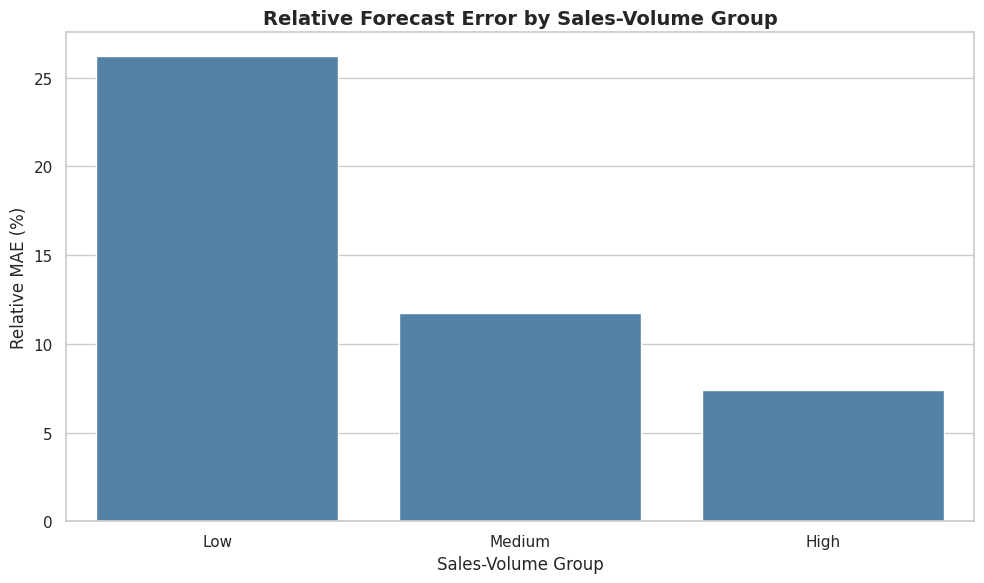

In [41]:

# ============================================================
# STEP 16: VISUALISE RELATIVE MAE BY SALES-VOLUME GROUP
# ============================================================

# Create a figure for the Relative MAE comparison.
plt.figure(figsize=(10, 6))

# Create a bar chart using the three sales-volume groups.
sns.barplot(
    data=volume_error_summary,
    x="Sales_Volume_Group",
    y="Relative_MAE_Percent",
    color="steelblue"
)

# Add a descriptive chart title.
plt.title(
    "Relative Forecast Error by Sales-Volume Group",
    fontsize=14,
    fontweight="bold"
)

# Label both axes.
plt.xlabel("Sales-Volume Group")
plt.ylabel("Relative MAE (%)")

# Display the chart.
plt.tight_layout()
plt.show()


In [42]:

# ============================================================
# STEP 17: FORECAST ERROR ANALYSIS BY PROMOTION STATUS
# ============================================================

# Group observations by promotion status.
promotion_error_summary = (
    df_forecast_analysis
    .groupby("Promotion_Flag")
    .agg(
        Total_Observations=("Forecast_Error", "count"),
        Average_Actual_Sales=("Units_Sold", "mean"),
        Average_Forecast=("Demand_Forecast", "mean"),
        MAE=("Absolute_Forecast_Error", "mean"),
        RMSE=("Forecast_Error", lambda x: np.sqrt(np.mean(x ** 2))),
        Mean_Forecast_Error=("Forecast_Error", "mean")
    )
    .reset_index()
)

# Calculate Relative MAE for each promotion group.
promotion_error_summary["Relative_MAE_Percent"] = (
    promotion_error_summary["MAE"]
    / promotion_error_summary["Average_Actual_Sales"]
) * 100

# Replace numeric promotion codes with readable labels.
promotion_error_summary["Promotion_Status"] = (
    promotion_error_summary["Promotion_Flag"]
    .map({0: "No Promotion", 1: "Promotion"})
)

# Display the results.
display(
    promotion_error_summary[
        [
            "Promotion_Status",
            "Total_Observations",
            "Average_Actual_Sales",
            "Average_Forecast",
            "MAE",
            "RMSE",
            "Mean_Forecast_Error",
            "Relative_MAE_Percent"
        ]
    ].round(4)
)


,Promotion_Status,Total_Observations,Average_Actual_Sales,Average_Forecast,MAE,RMSE,Mean_Forecast_Error,Relative_MAE_Percent
0,No Promotion,81980,19.50,19.53,2.38,2.99,-0.03,12.21
1,Promotion,9270,24.91,24.93,2.36,2.97,-0.01,9.47


### Forecast Error Analysis by Promotion Status

Forecast errors were compared between observations with and without promotions using MAE, RMSE, Mean Forecast Error and Relative MAE.

The dataset contained 81,980 observations without promotions and 9,270 observations with promotions.

Average actual sales were 24.91 units during promotion observations, compared with 19.50 units during non-promotion observations.

The promotion group recorded an MAE of 2.36 units and RMSE of 2.97 units. The non-promotion group recorded an MAE of 2.38 units and RMSE of 2.99 units.

These differences in absolute forecast error were small.

Relative MAE was 9.47% for promotion observations and 12.21% for non-promotion observations. This indicates that absolute forecast errors represented a smaller proportion of average actual sales in the promotion group.

Mean Forecast Error was close to zero in both groups, suggesting limited overall directional bias.

Although average actual sales were higher during promotion observations, this descriptive comparison does not establish that promotions caused increased sales or improved forecasting accuracy. Differences in sales volume and other factors may influence the observed results.

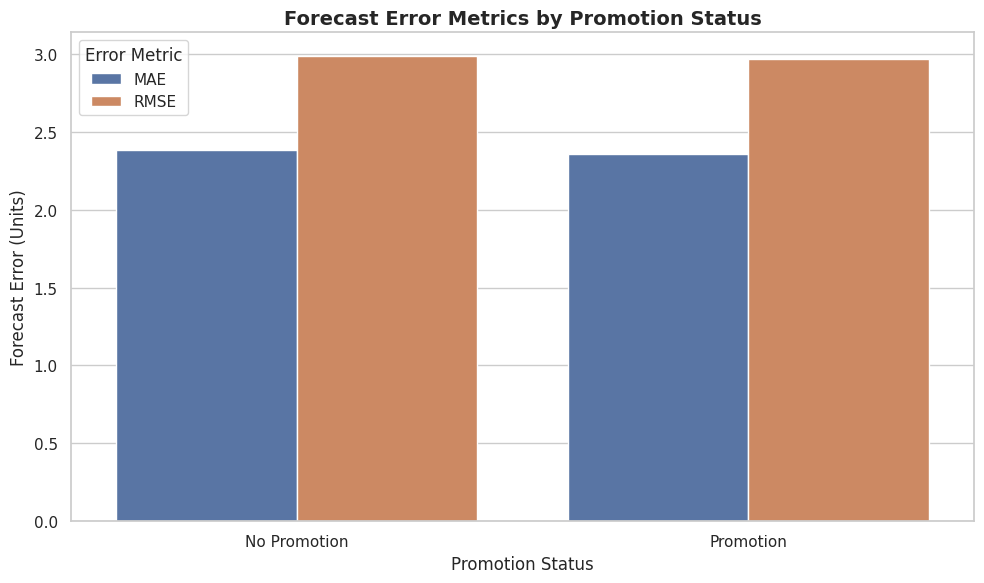

In [43]:

# ============================================================
# STEP 18: VISUALISE FORECAST ERRORS BY PROMOTION STATUS
# ============================================================

# Reshape the summary table to make the two error metrics
# suitable for a grouped bar chart.
promotion_error_plot = promotion_error_summary.melt(
    id_vars="Promotion_Status",
    value_vars=["MAE", "RMSE"],
    var_name="Error_Metric",
    value_name="Error_Value"
)

# Create the grouped bar chart.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=promotion_error_plot,
    x="Promotion_Status",
    y="Error_Value",
    hue="Error_Metric"
)

# Add chart title and axis labels.
plt.title(
    "Forecast Error Metrics by Promotion Status",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Promotion Status")
plt.ylabel("Forecast Error (Units)")

# Display the legend and chart.
plt.legend(title="Error Metric")
plt.tight_layout()
plt.show()


In [44]:

# ============================================================
# STEP 19: FORECAST ERROR ANALYSIS BY REGION
# ============================================================

# Group observations by region and calculate forecast metrics.
region_forecast_summary = (
    df_forecast_analysis
    .groupby("Region")
    .agg(
        Total_Observations=("Forecast_Error", "count"),
        Mean_Forecast_Error=("Forecast_Error", "mean"),
        MAE=("Absolute_Forecast_Error", "mean"),
        RMSE=("Forecast_Error", lambda x: np.sqrt(np.mean(x ** 2))),
        Average_Actual_Sales=("Units_Sold", "mean"),
        Average_Forecast=("Demand_Forecast", "mean")
    )
    .reset_index()
)

# Calculate Relative MAE for each region.
region_forecast_summary["Relative_MAE_Percent"] = (
    region_forecast_summary["MAE"]
    / region_forecast_summary["Average_Actual_Sales"]
) * 100

# Sort the regions by MAE.
region_forecast_summary = (
    region_forecast_summary
    .sort_values("MAE")
    .reset_index(drop=True)
)

# Display the regional forecast evaluation results.
display(region_forecast_summary.round(4))


,Region,Total_Observations,Mean_Forecast_Error,MAE,RMSE,Average_Actual_Sales,Average_Forecast,Relative_MAE_Percent
0,East,22934,-0.02,2.38,2.98,20.06,20.08,11.85
1,North,22974,-0.01,2.38,2.99,20.02,20.02,11.88
2,South,22720,-0.04,2.38,2.99,20.11,20.15,11.85
3,West,22622,-0.05,2.38,2.99,20.03,20.08,11.89


### Forecast Error Analysis by Region

Forecast evaluation metrics were calculated separately for the four geographical regions: East, North, South and West.

The analysis covered 91,250 observations, with regional observation counts ranging from 22,622 to 22,974.

All four regions recorded an MAE of approximately 2.38 units. RMSE values ranged from 2.98 to 2.99 units, while Relative MAE ranged from 11.85% to 11.89%.

Mean Forecast Error was slightly negative across all four regions, indicating negligible average overforecasting tendencies.

Average actual sales were also similar, ranging from 20.02 to 20.11 units.

Overall, the regional results indicate highly consistent recorded forecast error metrics across the four regions. The differences are small in the reported figures and do not establish statistically significant differences in forecasting performance.

Further inferential analysis would be required to determine whether any underlying regional differences exist.

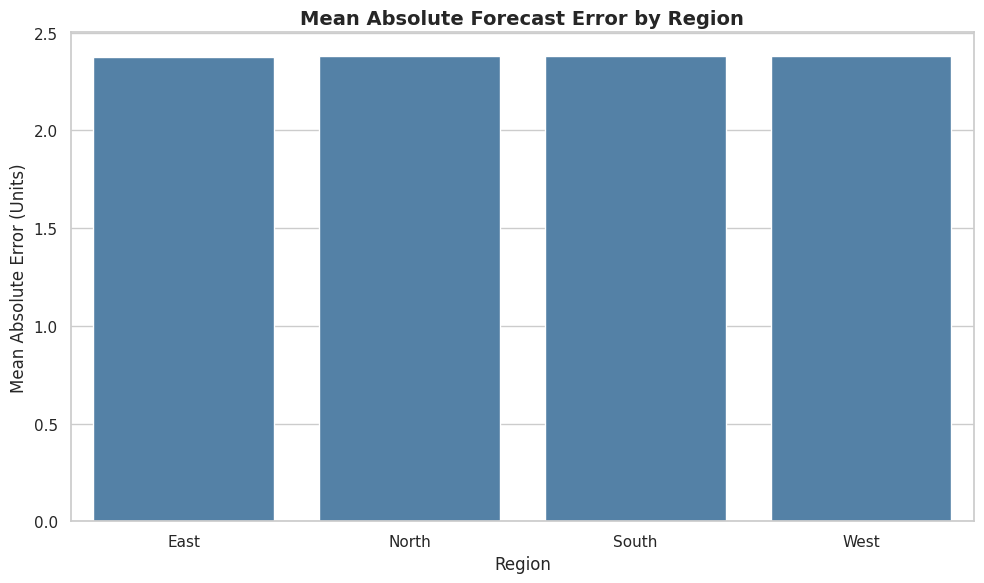

In [45]:

# ============================================================
# STEP 20: VISUALISE MAE BY REGION
# ============================================================

# Create a figure for the regional MAE comparison.
plt.figure(figsize=(10, 6))

# Create a bar chart of regional MAE values.
sns.barplot(
    data=region_forecast_summary,
    x="Region",
    y="MAE",
    color="steelblue"
)

# Add a descriptive title.
plt.title(
    "Mean Absolute Forecast Error by Region",
    fontsize=14,
    fontweight="bold"
)

# Label the axes.
plt.xlabel("Region")
plt.ylabel("Mean Absolute Error (Units)")

# Improve spacing and display the chart.
plt.tight_layout()
plt.show()


In [46]:

# ============================================================
# STEP 21: FORECAST ERROR ANALYSIS BY SUPPLIER
# ============================================================

# Group observations by supplier and calculate forecast metrics.
supplier_forecast_summary = (
    df_forecast_analysis
    .groupby("Supplier_ID")
    .agg(
        Total_Observations=("Forecast_Error", "count"),
        Mean_Forecast_Error=("Forecast_Error", "mean"),
        MAE=("Absolute_Forecast_Error", "mean"),
        RMSE=(
            "Forecast_Error",
            lambda x: np.sqrt(np.mean(x ** 2))
        ),
        Average_Actual_Sales=("Units_Sold", "mean"),
        Average_Forecast=("Demand_Forecast", "mean")
    )
    .reset_index()
)

# Calculate Relative MAE for each supplier.
supplier_forecast_summary["Relative_MAE_Percent"] = (
    supplier_forecast_summary["MAE"]
    / supplier_forecast_summary["Average_Actual_Sales"]
) * 100

# Sort suppliers by MAE from lowest to highest.
supplier_forecast_summary = (
    supplier_forecast_summary
    .sort_values("MAE")
    .reset_index(drop=True)
)

# Display the supplier-level forecast evaluation results.
display(supplier_forecast_summary.round(4))


,Supplier_ID,Total_Observations,Mean_Forecast_Error,MAE,RMSE,Average_Actual_Sales,Average_Forecast,Relative_MAE_Percent
0,SUP_9,5840,0.08,2.36,2.97,20.08,20.00,11.75
1,SUP_7,12410,-0.02,2.36,2.97,20.05,20.07,11.77
2,SUP_8,10220,-0.07,2.37,2.99,20.10,20.17,11.81
3,SUP_3,8395,-0.02,2.38,2.99,20.01,20.04,11.87
4,SUP_2,9490,-0.05,2.38,2.99,20.13,20.18,11.83
5,SUP_5,8395,-0.05,2.38,3.00,20.03,20.08,11.90
6,SUP_6,7300,-0.06,2.39,2.98,20.09,20.16,11.88
7,SUP_1,10220,-0.01,2.39,2.99,19.99,19.99,11.95
8,SUP_10,9855,-0.04,2.39,2.99,20.01,20.06,11.94
9,SUP_4,9125,0.00,2.40,3.01,20.07,20.07,11.95



### Forecast Error Analysis by Supplier

Forecast evaluation metrics were calculated separately for all ten suppliers using MAE, RMSE, Mean Forecast Error and Relative MAE.

The number of observations varied across suppliers, ranging from 5,840 for SUP_9 to 12,410 for SUP_7.

SUP_9 and SUP_7 recorded the lowest MAE values at 2.36 units, while SUP_4 recorded the highest MAE at 2.40 units. The difference between the lowest and highest supplier-level MAE was only 0.04 units.

RMSE values ranged from 2.97 to 3.01 units, indicating similarly small differences in the magnitude of forecast errors.

Relative MAE ranged from 11.75% for SUP_9 to 11.95% for SUP_1 and SUP_4. This narrow range suggests that relative forecast errors were also similar across suppliers.

Mean Forecast Error ranged from -0.07 to 0.08 units. SUP_9 recorded the largest positive average error, indicating slight underforecasting, while SUP_8 recorded the largest negative average error, indicating slight overforecasting.

Overall, the results indicate relatively consistent recorded forecast error metrics across the ten suppliers.

These findings are descriptive and do not establish statistically significant differences between suppliers. They also do not demonstrate differences in supplier reliability, operational efficiency or overall performance.


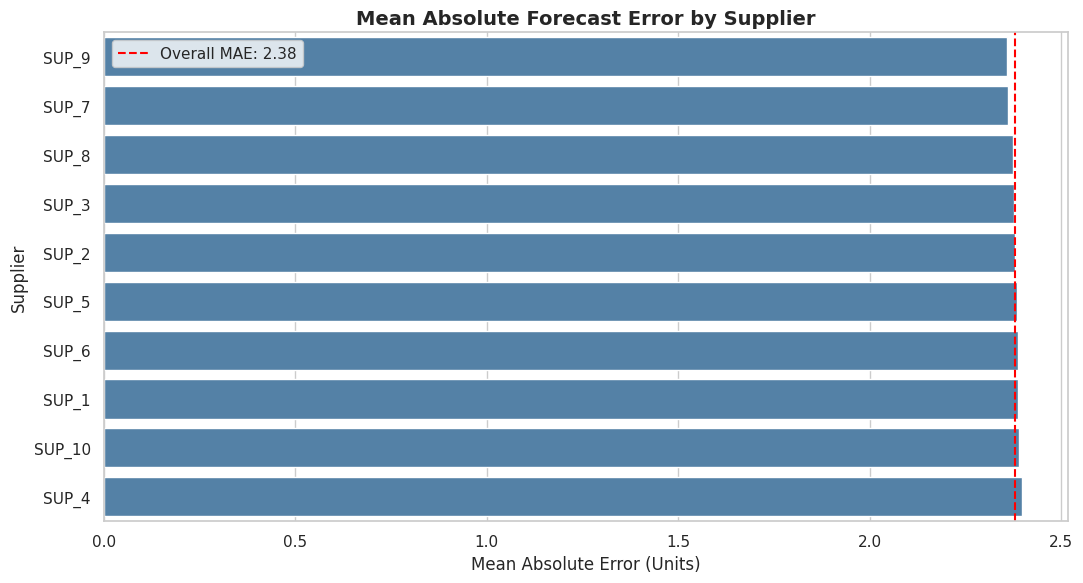

In [47]:

# ============================================================
# STEP 22: VISUALISE FORECAST MAE BY SUPPLIER
# ============================================================

# Calculate the overall MAE across all observations.
overall_mae = df_forecast_analysis["Absolute_Forecast_Error"].mean()

# Create a horizontal bar chart of supplier-level MAE.
plt.figure(figsize=(11, 6))

sns.barplot(
    data=supplier_forecast_summary,
    x="MAE",
    y="Supplier_ID",
    color="steelblue"
)

# Add a vertical reference line for the overall MAE.
plt.axvline(
    overall_mae,
    color="red",
    linestyle="--",
    label=f"Overall MAE: {overall_mae:.2f}"
)

# Add chart title and axis labels.
plt.title(
    "Mean Absolute Forecast Error by Supplier",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Mean Absolute Error (Units)")
plt.ylabel("Supplier")

# Display the reference-line legend.
plt.legend()

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()



### Forecast Error Analysis by Supplier

Forecast evaluation metrics were calculated separately for all 10 suppliers using MAE, RMSE, Mean Forecast Error and Relative MAE.

SUP_9 and SUP_7 recorded the lowest MAE values at 2.36 units, while SUP_4 recorded the highest MAE at 2.40 units. The difference between the lowest and highest supplier-level MAE was approximately 0.04 units, indicating very limited variation in average absolute forecast errors.

RMSE values ranged from 2.97 to 3.01 units, also indicating relatively similar error magnitudes across suppliers.

Mean Forecast Error ranged from -0.07 to 0.08 units. SUP_9 recorded a positive mean error, indicating slight average underforecasting, while most other suppliers recorded small negative values, indicating slight average overforecasting.

Relative MAE ranged from 11.75% for SUP_9 to 11.95% for SUP_1 and SUP_4. This narrow range suggests that relative forecast errors were also similar across suppliers.

The number of observations varied across suppliers, from 5,840 for SUP_9 to 12,410 for SUP_7. These differences in sample size should be considered when interpreting the comparisons.

Overall, the results indicate relatively consistent recorded forecast error metrics across suppliers. The observed differences are small and do not establish statistically significant differences in forecasting performance or supplier operational efficiency.

The analysis evaluates the forecast values supplied in the dataset. The forecasting method, forecast generation date and forecast horizon are unknown; therefore, these results should not be interpreted as evidence of out-of-sample predictive performance.


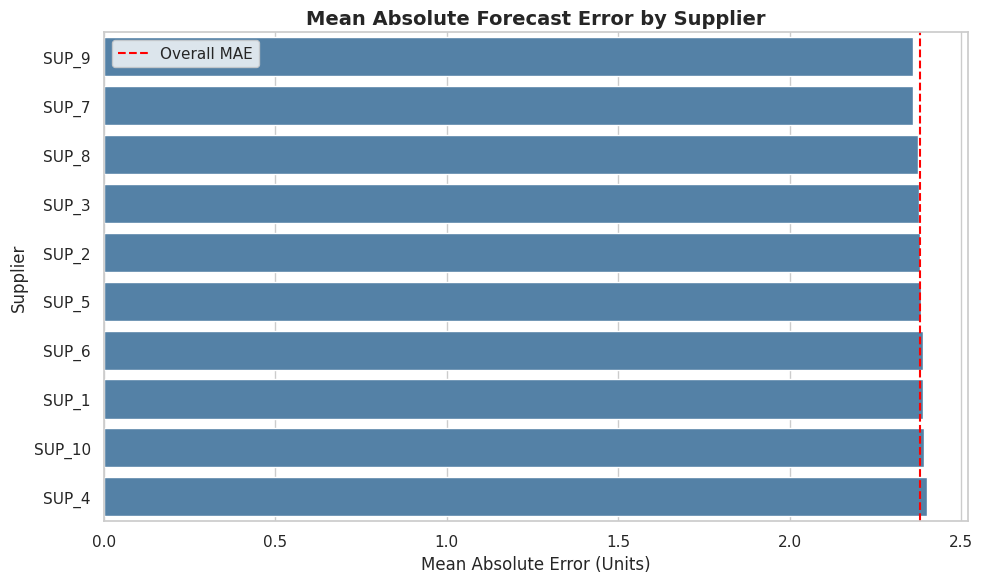

In [49]:

# ============================================================
# STEP 22: VISUALISE MAE BY SUPPLIER
# ============================================================

# Create a horizontal bar chart of supplier-level MAE.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=supplier_forecast_summary,
    x="MAE",
    y="Supplier_ID",
    color="steelblue"
)

# Add a reference line representing the overall MAE.
plt.axvline(
    x=df_forecast_analysis["Absolute_Forecast_Error"].mean(),
    color="red",
    linestyle="--",
    label="Overall MAE"
)

# Add chart title and axis labels.
plt.title(
    "Mean Absolute Forecast Error by Supplier",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Mean Absolute Error (Units)")
plt.ylabel("Supplier")

# Display the reference-line legend.
plt.legend()

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()


In [50]:

# ============================================================
# STEP 23: CONSOLIDATED FORECAST EVALUATION SUMMARY
# ============================================================

# Create copies so that the original summary tables remain unchanged.
warehouse_summary = warehouse_forecast_summary.copy()
sku_summary = sku_forecast_summary.copy()
supplier_summary = supplier_forecast_summary.copy()
region_summary = region_forecast_summary.copy()
monthly_summary = monthly_forecast_summary.copy()

# Calculate Relative MAE where it has not already been calculated.
# Relative MAE = (MAE / Average Actual Sales) * 100.
summary_tables = {
    "Warehouse": warehouse_summary,
    "SKU": sku_summary,
    "Supplier": supplier_summary,
    "Region": region_summary,
    "Month": monthly_summary
}

for analysis_level, summary in summary_tables.items():

    # Calculate Relative MAE if the column does not already exist.
    if "Relative_MAE_Percent" not in summary.columns:
        summary["Relative_MAE_Percent"] = (
            summary["MAE"] / summary["Average_Actual_Sales"]
        ) * 100

# Build a consolidated comparison across the five analysis levels.
consolidated_forecast_summary = pd.DataFrame([
    {
        "Analysis_Level": analysis_level,
        "Number_of_Groups": len(summary),
        "Total_Observations": summary["Total_Observations"].sum(),
        "Average_MAE": summary["MAE"].mean(),
        "Minimum_MAE": summary["MAE"].min(),
        "Maximum_MAE": summary["MAE"].max(),
        "MAE_Range": summary["MAE"].max() - summary["MAE"].min(),
        "Average_RMSE": summary["RMSE"].mean(),
        "Average_Relative_MAE_Percent": (
            summary["Relative_MAE_Percent"].mean()
        )
    }
    for analysis_level, summary in summary_tables.items()
])

# Display the consolidated comparison, rounded to four decimals.
display(consolidated_forecast_summary.round(4))


,Analysis_Level,Number_of_Groups,Total_Observations,Average_MAE,Minimum_MAE,Maximum_MAE,MAE_Range,Average_RMSE,Average_Relative_MAE_Percent
0,Warehouse,5,91250,2.38,2.36,2.39,0.03,2.99,11.87
1,SKU,50,91250,2.38,2.30,2.45,0.15,2.99,11.87
2,Supplier,10,91250,2.38,2.36,2.40,0.04,2.99,11.87
3,Region,4,91250,2.38,2.38,2.38,0.01,2.99,11.87
4,Month,12,91250,2.38,2.30,2.42,0.12,2.99,13.68


In [51]:

# ============================================================
# STEP 24: VALIDATE SUBGROUP METRICS AGAINST OVERALL RESULTS
# ============================================================

# Calculate the overall forecast evaluation metrics directly.
overall_forecast_metrics = {
    "Total_Observations": len(df_forecast_analysis),

    "Overall_MAE": (
        df_forecast_analysis["Absolute_Forecast_Error"].mean()
    ),

    "Overall_RMSE": np.sqrt(
        np.mean(df_forecast_analysis["Forecast_Error"] ** 2)
    ),

    "Overall_Mean_Forecast_Error": (
        df_forecast_analysis["Forecast_Error"].mean()
    ),

    "Average_Actual_Sales": (
        df_forecast_analysis["Units_Sold"].mean()
    ),

    "Average_Forecast": (
        df_forecast_analysis["Demand_Forecast"].mean()
    )
}

# Calculate overall Relative MAE.
overall_forecast_metrics["Overall_Relative_MAE_Percent"] = (
    overall_forecast_metrics["Overall_MAE"]
    / overall_forecast_metrics["Average_Actual_Sales"]
) * 100

# Convert the overall metrics into a DataFrame for display.
overall_forecast_summary = pd.DataFrame(
    [overall_forecast_metrics]
)

# Display the overall forecast evaluation results.
display(overall_forecast_summary.round(4))


# ------------------------------------------------------------
# Validate weighted subgroup MAE and RMSE for each dimension.
# ------------------------------------------------------------

validation_results = []

for analysis_level, summary in summary_tables.items():

    # Calculate observation-weighted MAE.
    weighted_mae = (
        summary["MAE"] * summary["Total_Observations"]
    ).sum() / summary["Total_Observations"].sum()

    # Calculate pooled RMSE using squared group-level RMSE.
    weighted_rmse = np.sqrt(
        (
            summary["RMSE"] ** 2
            * summary["Total_Observations"]
        ).sum()
        / summary["Total_Observations"].sum()
    )

    # Calculate observation-weighted mean forecast error.
    weighted_mean_error = (
        summary["Mean_Forecast_Error"]
        * summary["Total_Observations"]
    ).sum() / summary["Total_Observations"].sum()

    # Record the validation results.
    validation_results.append({
        "Analysis_Level": analysis_level,
        "Weighted_MAE": weighted_mae,
        "Weighted_RMSE": weighted_rmse,
        "Weighted_Mean_Forecast_Error": weighted_mean_error,
        "Overall_MAE": overall_forecast_metrics["Overall_MAE"],
        "Overall_RMSE": overall_forecast_metrics["Overall_RMSE"],
        "Overall_Mean_Forecast_Error": (
            overall_forecast_metrics["Overall_Mean_Forecast_Error"]
        )
    })

# Convert validation results into a DataFrame.
forecast_validation_summary = pd.DataFrame(validation_results)

# Display the validation results.
display(forecast_validation_summary.round(6))


,Total_Observations,Overall_MAE,Overall_RMSE,Overall_Mean_Forecast_Error,Average_Actual_Sales,Average_Forecast,Overall_Relative_MAE_Percent
0,91250,2.38,2.99,-0.03,20.05,20.08,11.87


,Analysis_Level,Weighted_MAE,Weighted_RMSE,Weighted_Mean_Forecast_Error,Overall_MAE,Overall_RMSE,Overall_Mean_Forecast_Error
0,Warehouse,2.38,2.99,-0.03,2.38,2.99,-0.03
1,SKU,2.38,2.99,-0.03,2.38,2.99,-0.03
2,Supplier,2.38,2.99,-0.03,2.38,2.99,-0.03
3,Region,2.38,2.99,-0.03,2.38,2.99,-0.03
4,Month,2.38,2.99,-0.03,2.38,2.99,-0.03


In [52]:

# ============================================================
# STEP 25: FINAL DATA QUALITY AND ANALYSIS VALIDATION
# ============================================================

# ------------------------------------------------------------
# 1. Check missing values.
# ------------------------------------------------------------

total_missing_values = df.isna().sum().sum()

# ------------------------------------------------------------
# 2. Check duplicate records.
# ------------------------------------------------------------

duplicate_rows = df.duplicated().sum()

# Check whether each SKU, warehouse and date combination is unique.
duplicate_business_keys = df.duplicated(
    subset=["Date", "SKU_ID", "Warehouse_ID"]
).sum()

# ------------------------------------------------------------
# 3. Check date continuity within each SKU-warehouse group.
# ------------------------------------------------------------

# Sort observations chronologically within each group.
df_quality = df.sort_values(
    ["SKU_ID", "Warehouse_ID", "Date"]
).copy()

# Calculate the number of days between consecutive observations.
df_quality["Date_Gap_Days"] = (
    df_quality.groupby(["SKU_ID", "Warehouse_ID"])["Date"]
    .diff()
    .dt.days
)

# Exclude the first observation in each group.
valid_date_gaps = df_quality["Date_Gap_Days"].dropna()

# Count date gaps that are not exactly one day.
irregular_date_gaps = (valid_date_gaps != 1).sum()

# ------------------------------------------------------------
# 4. Check negative and infinite numeric values.
# ------------------------------------------------------------

# Select numeric columns only.
numeric_columns = df.select_dtypes(include=np.number)

# Count negative values across numeric columns.
negative_values = (numeric_columns < 0).sum().sum()

# Count positive and negative infinity values.
infinite_values = np.isinf(numeric_columns).sum().sum()

# ------------------------------------------------------------
# 5. Identify constant columns.
# ------------------------------------------------------------

# Find columns with only one unique value.
constant_columns = [
    column
    for column in df.columns
    if df[column].nunique(dropna=False) <= 1
]

# ------------------------------------------------------------
# 6. Validate binary flag columns.
# ------------------------------------------------------------

# Check whether Promotion_Flag contains only 0 and 1.
promotion_flag_valid = set(
    df["Promotion_Flag"].dropna().unique()
).issubset({0, 1})

# Check whether Stockout_Flag contains only 0 and 1.
stockout_flag_valid = set(
    df["Stockout_Flag"].dropna().unique()
).issubset({0, 1})

# Count the number of distinct Stockout_Flag values.
stockout_flag_unique_values = (
    df["Stockout_Flag"].nunique(dropna=True)
)

# ------------------------------------------------------------
# 7. Validate the forecast error calculation.
# ------------------------------------------------------------

# Recalculate forecast errors independently.
recalculated_forecast_error = (
    df_forecast_analysis["Units_Sold"]
    - df_forecast_analysis["Demand_Forecast"]
)

# Compare recalculated errors with the existing column.
forecast_error_consistent = np.isclose(
    recalculated_forecast_error,
    df_forecast_analysis["Forecast_Error"]
).all()

# ------------------------------------------------------------
# 8. Compile the final quality assessment.
# ------------------------------------------------------------

final_quality_checks = pd.DataFrame({
    "Quality_Check": [
        "Dataset contains 91,250 observations",
        "Dataset contains 15 columns",
        "Missing values",
        "Duplicate complete records",
        "Duplicate SKU-Warehouse-Date combinations",
        "Irregular consecutive date gaps",
        "Negative numeric values",
        "Infinite numeric values",
        "Promotion_Flag contains only 0 and 1",
        "Stockout_Flag contains only 0 and 1",
        "Forecast error calculations are consistent"
    ],

    "Result": [
        df.shape[0] == 91250,
        df.shape[1] == 15,
        total_missing_values == 0,
        duplicate_rows == 0,
        duplicate_business_keys == 0,
        irregular_date_gaps == 0,
        negative_values == 0,
        infinite_values == 0,
        promotion_flag_valid,
        stockout_flag_valid,
        forecast_error_consistent
    ],

    "Observed_Value": [
        df.shape[0],
        df.shape[1],
        total_missing_values,
        duplicate_rows,
        duplicate_business_keys,
        irregular_date_gaps,
        negative_values,
        infinite_values,
        sorted(df["Promotion_Flag"].dropna().unique().tolist()),
        sorted(df["Stockout_Flag"].dropna().unique().tolist()),
        forecast_error_consistent
    ]
})

# Display the final quality assessment.
display(final_quality_checks)

# Display constant columns separately.
print("Constant columns:", constant_columns)

# Display the dataset date range.
print("Dataset start date:", df["Date"].min())
print("Dataset end date:", df["Date"].max())

# Display the number of SKU-warehouse combinations.
print(
    "SKU-Warehouse combinations:",
    df.groupby(["SKU_ID", "Warehouse_ID"]).ngroups
)


,Quality_Check,Result,Observed_Value
0,"Dataset contains 91,250 observations",True,91250
1,Dataset contains 15 columns,True,15
2,Missing values,True,0
3,Duplicate complete records,True,0
4,Duplicate SKU-Warehouse-Date combinations,True,0
5,Irregular consecutive date gaps,True,0
6,Negative numeric values,True,0
7,Infinite numeric values,True,0
8,Promotion_Flag contains only 0 and 1,True,"[0, 1]"
9,Stockout_Flag contains only 0 and 1,True,[0]


Constant columns: ['Stockout_Flag']
Dataset start date: 2024-01-01 00:00:00
Dataset end date: 2024-12-30 00:00:00
SKU-Warehouse combinations: 250



## Final Data Quality Assessment

A final data quality assessment was conducted to evaluate the structural consistency and analytical readiness of the supply chain dataset.

The dataset contains 91,250 observations and 15 columns, covering the period from 1 January 2024 to 30 December 2024.

The assessment confirmed the following:

- No missing values were identified.
- No duplicate complete records were identified.
- No duplicate Date-SKU-Warehouse combinations were identified.
- All 250 SKU-warehouse combinations had continuous daily observations, with no irregular date gaps.
- No negative or infinite numeric values were identified.
- Promotion_Flag contained valid binary values of 0 and 1.
- Forecast error calculations were independently recalculated and validated.

One important limitation was identified in Stockout_Flag. The column contained only zero values across all 91,250 observations, making it a constant variable with no analytical variation.

Although the column contains valid binary values, its lack of variation means it cannot distinguish stockout from non-stockout observations. It has therefore been retained in the original dataset but should not be used for stockout classification or predictive analysis without further clarification of its source.

Overall, the dataset passed the structural and consistency checks performed in this notebook. However, passing these checks does not independently establish the accuracy or real-world validity of every variable. The documented Stockout_Flag limitation and other uncertainties about variable definitions should be considered in subsequent analyses.



## Exploratory Data Analysis — Overall Conclusions

The exploratory analysis examined the structure, quality, sales patterns, inventory movements, replenishment behaviour and supplied demand forecasts within the supply chain dataset.

The dataset contains 91,250 daily observations across 50 SKUs, five warehouses, 10 suppliers and four geographical regions.

### 1. Data Quality and Structure

The dataset passed the structural checks performed during the analysis. No missing values, duplicate records, duplicate business keys, irregular daily date gaps, negative numeric values or infinite values were identified.

However, Stockout_Flag contained only zero values, limiting its usefulness for stockout-related analysis.

### 2. Sales and Demand

Average actual sales were approximately 20.05 units, compared with average forecasted demand of approximately 20.08 units.

Both distributions were approximately symmetric, with relatively similar means and medians.

The similarity between the distributions does not, by itself, establish individual forecast accuracy.

### 3. Inventory and Replenishment

The inventory reconciliation analysis demonstrated that the relationship between previous inventory, recorded order quantity, units sold and current inventory balanced exactly across the 91,000 observations with available previous inventory.

Positive replenishment quantities represented approximately 5.51% of all observations.

The dataset also showed a deterministic relationship between previous inventory position and positive replenishment observations. This appears to reflect an internal dataset replenishment rule, although the actual operational meaning of the order quantity requires confirmation.

### 4. Forecast Evaluation

The supplied demand forecasts recorded an overall MAE of approximately 2.38 units and RMSE of approximately 2.99 units.

Mean Forecast Error was approximately -0.03 units, indicating negligible overall directional bias.

Forecast error metrics were relatively consistent across suppliers, warehouses, SKUs and regions.

Monthly absolute forecast errors were also relatively stable. However, Relative MAE increased during lower-volume months, demonstrating the importance of considering sales volume when interpreting absolute forecast errors.

The analysis also identified a strong negative association between monthly average sales and Relative MAE. This relationship should be interpreted cautiously because average sales form the denominator of Relative MAE, and the correlation was based on only 12 monthly observations.

### 5. Limitations

The following limitations should be considered:

- The dataset covers only one calendar year.
- The forecasting method and forecast horizon are unknown.
- The Stockout_Flag variable has no variation.
- Some variable definitions and operational assumptions remain unconfirmed.
- Most comparisons performed in this notebook are descriptive and do not establish causation or statistically significant differences.

### 6. Next Analytical Stage

The next stage will use statistical methods to investigate relationships between variables, test appropriate hypotheses, estimate uncertainty and assess whether observed differences are statistically meaningful.

The results of this exploratory analysis will guide the selection of appropriate statistical tests and subsequent predictive modelling.
